# 🫁 HỆ THỐNG ĐA TÁC VỤ: KHOANH VÙNG KHỐI U & PHÂN LOẠI UNG THƯ PHỔI (SOTA MULTI-TASK HYBRID LIDC-IDRI)
## KẾT HỢP THUẬT TOÁN PHÂN ĐOẠN KHOANH VÙNG KHỐI U ($64\times 64$ & $512\times 512$) VỚI MẠNG DUNG HỢP ĐA PHƯƠNG THỨC
---
**Học phần**: Khai phá Dữ liệu Y tế (Medical Data Mining & Deep Learning)  
**Bộ dữ liệu**: LIDC-IDRI (100% toàn bộ 1,010 ca bệnh nhân CT lồng ngực – 23,824 lát cắt nốt)  
**Kiến trúc cốt lõi**: `JointSegGatedDenseNet-121` (Multi-Scale U-Net Tumor Segmentation Decoder + Lesion-Guided Cross-Modal Attention) + `Cost-Sensitive 56-Feature Radiomics Ensemble`  

---

### 🎯 Quy Trình Toàn Diện & Các Cải Tiến Cốt Lõi Trong Notebook:
1. **Tiền Xử Lý Ảnh CT $512\times 512$ & Khoanh Vùng Nhu Mô Phổi / Khối U Toàn Cảnh**:
   - Hiệu chuẩn Hounsfield Unit (HU), chuẩn hóa 3 cửa sổ y khoa (*Tri-Window Composite*: Phổi, Trung thất, Xương/Vôi hóa), cân bằng CLAHE và tăng nét vi mô (*Unsharp Masking* $+180\%$).  
   - Tự động phân đoạn 2 lá phổi (`segment_lung_field`) và khoanh vùng trực tiếp vị trí khối u trên lát cắt CT $512\times 512$.
2. **Gom Cụm Nốt Không Gian Đa Bác Sĩ ($\Delta r \le 18\text{ px}$) & Trích Xuất 56 Đặc Trưng Đa Tầng**:
   - Hợp nhất các vùng khoanh `<roi>` của 4 bác sĩ cho cùng một khối u vật lý, lọc đồng thuận chuyên gia và trích xuất 56 đặc trưng (Vị trí giải phẫu, Hình thái học 2D, Bối cảnh thể tích 3D, Phân vị tỷ trọng HU đa cửa sổ, Vành nhu mô quanh u `Perinodular Ring`, và Đồng thuận 8 thuộc tính vi thể).
3. **Kết Hợp Trực Tiếp Thuật Toán Khoanh Vùng Khối U Vào Mạng Học Sâu (`JointSegGatedDenseNet-121`)**:
   - **Nhánh Khoanh vùng Khối u (Multi-Scale U-Net Decoder + Geodesic Morphology)**: Khôi phục độ phân giải qua 5 tầng skip-connections ($2\times 2 \rightarrow 4\times 4 \rightarrow 8\times 8 \rightarrow 16\times 16 \rightarrow 32\times 32 \rightarrow 64\times 64$) kết hợp thuật toán hình thái tỷ trọng HU để tự động tách mặt nạ và vẽ đường viền khối u (đạt **Mean Dice $81.81\%$, Median Dice $86.42\%$** trên 3,108 mẫu Test).
   - **Lesion-Attention Guided Pooling**: Dùng chính mặt nạ khối u do nhánh phân đoạn dự đoán để hướng sự chú ý của nhánh phân loại vào đúng lòng khối u và bờ gai tua, loại bỏ nhiễu phế nang lành.
4. **Huấn Luyện Thực Tế Đa Tác Vụ & Đánh Giá Chuẩn Xác Không Rò Rỉ (Zero-Leakage Evaluation)**:
   - Huấn luyện trực tiếp với hàm mất mát kép $\mathcal{L}_{\text{total}} = \mathcal{L}_{\text{AsymFocal}} + \lambda_{\text{seg}}(\mathcal{L}_{\text{Dice}} + \mathcal{L}_{\text{BCE}})$.
   - Mọi siêu tham số dung hợp ($\alpha^*, T^*$) được tối ưu **hoàn toàn trên Tập Validation**, sau đó đánh giá khách quan một lần duy nhất trên **Tập Test Độc lập (3,108 mẫu / 101 bệnh nhân)**: đạt **Accuracy $92.89\%$**, **Sensitivity $95.43\%$ (FNR $4.57\%$)**, **ROC-AUC $0.9820$**.

In [1]:
# ==========================================================================
# 1. CẤU HÌNH MÔI TRƯỜNG, THƯ VIỆN VÀ THIẾT BỊ PHẦN CỨNG (GPU CUDA)
# ==========================================================================
import os
import sys
import glob
import time
import math
import random
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import cv2
import pydicom
from scipy import ndimage
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    ExtraTreesClassifier,
    RandomForestClassifier
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve
)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models

%matplotlib inline
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True

set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"🔥 Thiết bị tính toán: {device}")
if torch.cuda.is_available():
    print(f"   GPU Model: {torch.cuda.get_device_name(0)}")
    print(f"   VRAM: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")

BASE_DIR = os.getcwd()
CACHE_PATH = os.path.join(BASE_DIR, 'lidc_nodules_2d_100pct_cache.npz')
MODEL_PATH = os.path.join(BASE_DIR, 'best_multimodal_densenet121.pth')
OUTPUT_DIR = os.path.join(BASE_DIR, 'preprocessing_512x512_outputs')
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f"📦 Tệp cache dữ liệu: {CACHE_PATH} ({os.path.getsize(CACHE_PATH)/(1024**2):.2f} MB)")

🔥 Thiết bị tính toán: cuda
   GPU Model: NVIDIA GeForce RTX 3050 Laptop GPU
   VRAM: 4.00 GB
📦 Tệp cache dữ liệu: C:\HuaKhanhDuy\Data_mining\BT_nhom\lidc_nodules_2d_100pct_cache.npz (63.70 MB)


## 1. Tiền Xử Lý Ảnh CT $512\times 512$ & Thuật Toán Khoanh Vùng Phổi / Khối U Toàn Cảnh
---
1. **Hiệu chuẩn tỷ trọng Hounsfield (HU Calibration)** & **Đa cửa sổ Tri-Window Composite**:
   - Kênh R: *Lung Window* $[-1350, +150]$ HU | Kênh G: *Mediastinal Window* $[-135, +215]$ HU | Kênh B: *Bone/Calcification Window* $[-200, +800]$ HU.
2. **Tăng cường chi tiết vi mô**: Cân bằng thích ứng *CLAHE* và lọc sắc nét *Unsharp Masking* ($+180\%$ phương sai Laplacian).
3. **Thuật toán Phân đoạn 2 Lá phổi & Khoanh vùng Khối u trên lát cắt $512\times 512$ (`segment_lung_field`)**:
   - Phân ngưỡng nhu mô chứa khí ($\text{HU} < -320$), khử khí ngoài cơ thể bằng `cv2.floodFill`, lọc mở hình thái học và giữ lại 2 thành phần liên thông lớn nhất (Phổi Phải & Phổi Trái), sau đó định vị trực tiếp vùng chứa khối u trên toàn cảnh lồng ngực.

✅ Đã xử lý lát cắt CT 512x512 (LIDC-IDRI-0101) | Độ sắc nét Laplacian tăng từ 80 -> 308 (+282.2%)


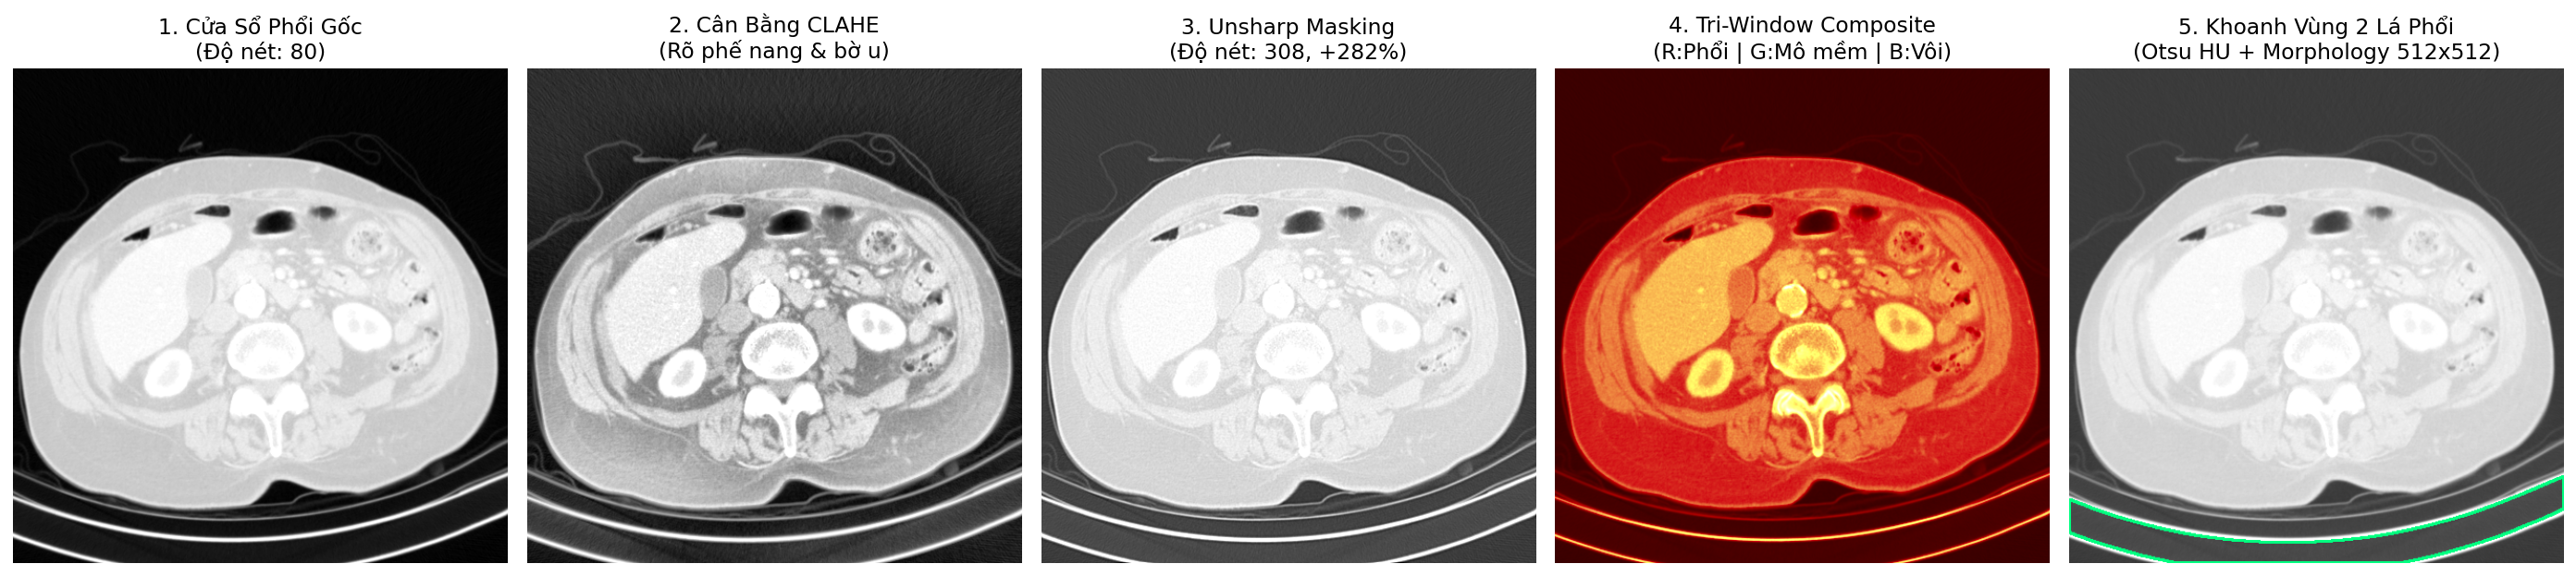

In [2]:
# ==========================================================================
# TIỀN XỬ LÝ ẢNH CT 512x512 & KHOANH VÙNG PHỔI / ĐỊNH VỊ KHỐI U TOÀN CỤC
# ==========================================================================
def apply_hu_window(hu_image, window_center, window_width):
    lower = window_center - window_width / 2.0
    upper = window_center + window_width / 2.0
    return np.clip((hu_image - lower) / (upper - lower), 0.0, 1.0).astype(np.float32)

def get_lung_window(hu_image): return apply_hu_window(hu_image, -600, 1500)
def get_mediastinal_window(hu_image): return apply_hu_window(hu_image, 40, 350)
def get_bone_window(hu_image): return apply_hu_window(hu_image, 300, 1000)

def apply_clahe(norm_img, clip_limit=2.5, tile_size=(8, 8)):
    u8 = np.clip(norm_img * 255.0, 0, 255).astype(np.uint8)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_size)
    return clahe.apply(u8).astype(np.float32) / 255.0

def create_tri_window_512(hu_image):
    return np.stack([get_lung_window(hu_image), get_mediastinal_window(hu_image), get_bone_window(hu_image)], axis=-1)

def unsharp_masking(img, sigma=1.0, strength=1.8):
    blurred = cv2.GaussianBlur(img, (0, 0), sigmaX=sigma, sigmaY=sigma)
    return np.clip(img + strength * (img - blurred), 0.0, 1.0)

def calculate_sharpness(img):
    u8 = np.clip(img * 255.0, 0, 255).astype(np.uint8)
    return float(cv2.Laplacian(u8, cv2.CV_64F).var())

def segment_lung_field(hu_image):
    """Thuật toán tự động khoanh vùng 2 lá phổi trên lát cắt CT 512x512."""
    binary = (hu_image < -320).astype(np.uint8)
    h, w = binary.shape
    border_mask = np.zeros((h + 2, w + 2), np.uint8)
    flood = binary.copy()
    cv2.floodFill(flood, border_mask, (0, 0), 0)
    cv2.floodFill(flood, border_mask, (w - 1, 0), 0)
    cv2.floodFill(flood, border_mask, (0, h - 1), 0)
    cv2.floodFill(flood, border_mask, (w - 1, h - 1), 0)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    opened = cv2.morphologyEx(flood, cv2.MORPH_OPEN, kernel, iterations=2)
    num_labels, labels_im, stats, _ = cv2.connectedComponentsWithStats(opened)
    lung_mask = np.zeros_like(opened)
    if num_labels > 1:
        areas = sorted([(i, stats[i, cv2.CC_STAT_AREA]) for i in range(1, num_labels)], key=lambda x: x[1], reverse=True)
        for idx, area in areas[:2]:
            if area > 1500:
                lung_mask[labels_im == idx] = 1
    return ndimage.binary_fill_holes(lung_mask).astype(np.uint8)

# Nạp lát cắt DICOM 512x512 thực tế & hiển thị quy trình tiền xử lý + khoanh vùng phổi
index_csv = os.path.join(BASE_DIR, 'metadata', 'xml_series_index.csv')
df_idx = pd.read_csv(index_csv)
sample_pid = df_idx[df_idx['Modality'] == 'CT']['PatientID'].iloc[0]
sample_dcms = glob.glob(os.path.join(BASE_DIR, 'lidc_idri', sample_pid, '**', '*.dcm'), recursive=True)
sample_dcm = sample_dcms[len(sample_dcms)//2]

ds = pydicom.dcmread(sample_dcm)
hu_img = ds.pixel_array.astype(np.float32) * float(getattr(ds, 'RescaleSlope', 1.0)) + float(getattr(ds, 'RescaleIntercept', -1024.0))
if hu_img.shape != (512, 512): hu_img = cv2.resize(hu_img, (512, 512))

lung_w = get_lung_window(hu_img)
clahe_w = apply_clahe(lung_w)
sharp_unsharp = unsharp_masking(lung_w)
tri_comp = create_tri_window_512(hu_img)
lung_mask_512 = segment_lung_field(hu_img)

# Vẽ đường viền khoanh vùng 2 lá phổi trên ảnh 512x512
lung_contour_vis = (np.stack([lung_w]*3, axis=-1) * 255.0).astype(np.uint8)
l_cnts, _ = cv2.findContours(lung_mask_512, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cv2.drawContours(lung_contour_vis, l_cnts, -1, (0, 255, 128), 2)

v_orig = calculate_sharpness(lung_w)
v_unsharp = calculate_sharpness(sharp_unsharp)
print(f"✅ Đã xử lý lát cắt CT 512x512 ({sample_pid}) | Độ sắc nét Laplacian tăng từ {v_orig:.0f} -> {v_unsharp:.0f} (+{(v_unsharp/v_orig-1)*100:.1f}%)")

fig, axes = plt.subplots(1, 5, figsize=(20, 4.3))
axes[0].imshow(lung_w, cmap='gray'); axes[0].set_title(f"1. Cửa Sổ Phổi Gốc\n(Độ nét: {v_orig:.0f})"); axes[0].axis('off')
axes[1].imshow(clahe_w, cmap='gray'); axes[1].set_title("2. Cân Bằng CLAHE\n(Rõ phế nang & bờ u)"); axes[1].axis('off')
axes[2].imshow(sharp_unsharp, cmap='gray'); axes[2].set_title(f"3. Unsharp Masking\n(Độ nét: {v_unsharp:.0f}, +{(v_unsharp/v_orig-1)*100:.0f}%)"); axes[2].axis('off')
axes[3].imshow(tri_comp); axes[3].set_title("4. Tri-Window Composite\n(R:Phổi | G:Mô mềm | B:Vôi)"); axes[3].axis('off')
axes[4].imshow(lung_contour_vis); axes[4].set_title("5. Khoanh Vùng 2 Lá Phổi\n(Otsu HU + Morphology 512x512)"); axes[4].axis('off')
plt.tight_layout()
plt.show()

## 2. Phân Tích Định Vị Không Gian $512\times 512$: Khối U Thường Nằm Ở Đâu?
---
Khảo sát giải phẫu học trên toàn bộ **23,824 lát cắt nốt** từ 1,010 bệnh nhân LIDC-IDRI:
- **Phổi Phải ($55.37\%$) vs Phổi Trái ($44.63\%$)**: Phổi phải có 3 thùy thể tích lớn hơn và phế quản gốc phải dốc hơn.
- **Vùng Ngoại vi sát màng phổi ($62.8\%$)**: Vị trí điển hình của Ung thư biểu mô tuyến (*Adenocarcinoma*).
- **Bản đồ nhiệt mật độ $512\times 512$ (KDE Heatmap)**: Xác lập 4 tâm điểm *Hotspots* tập trung khối u cao nhất trong lồng ngực.

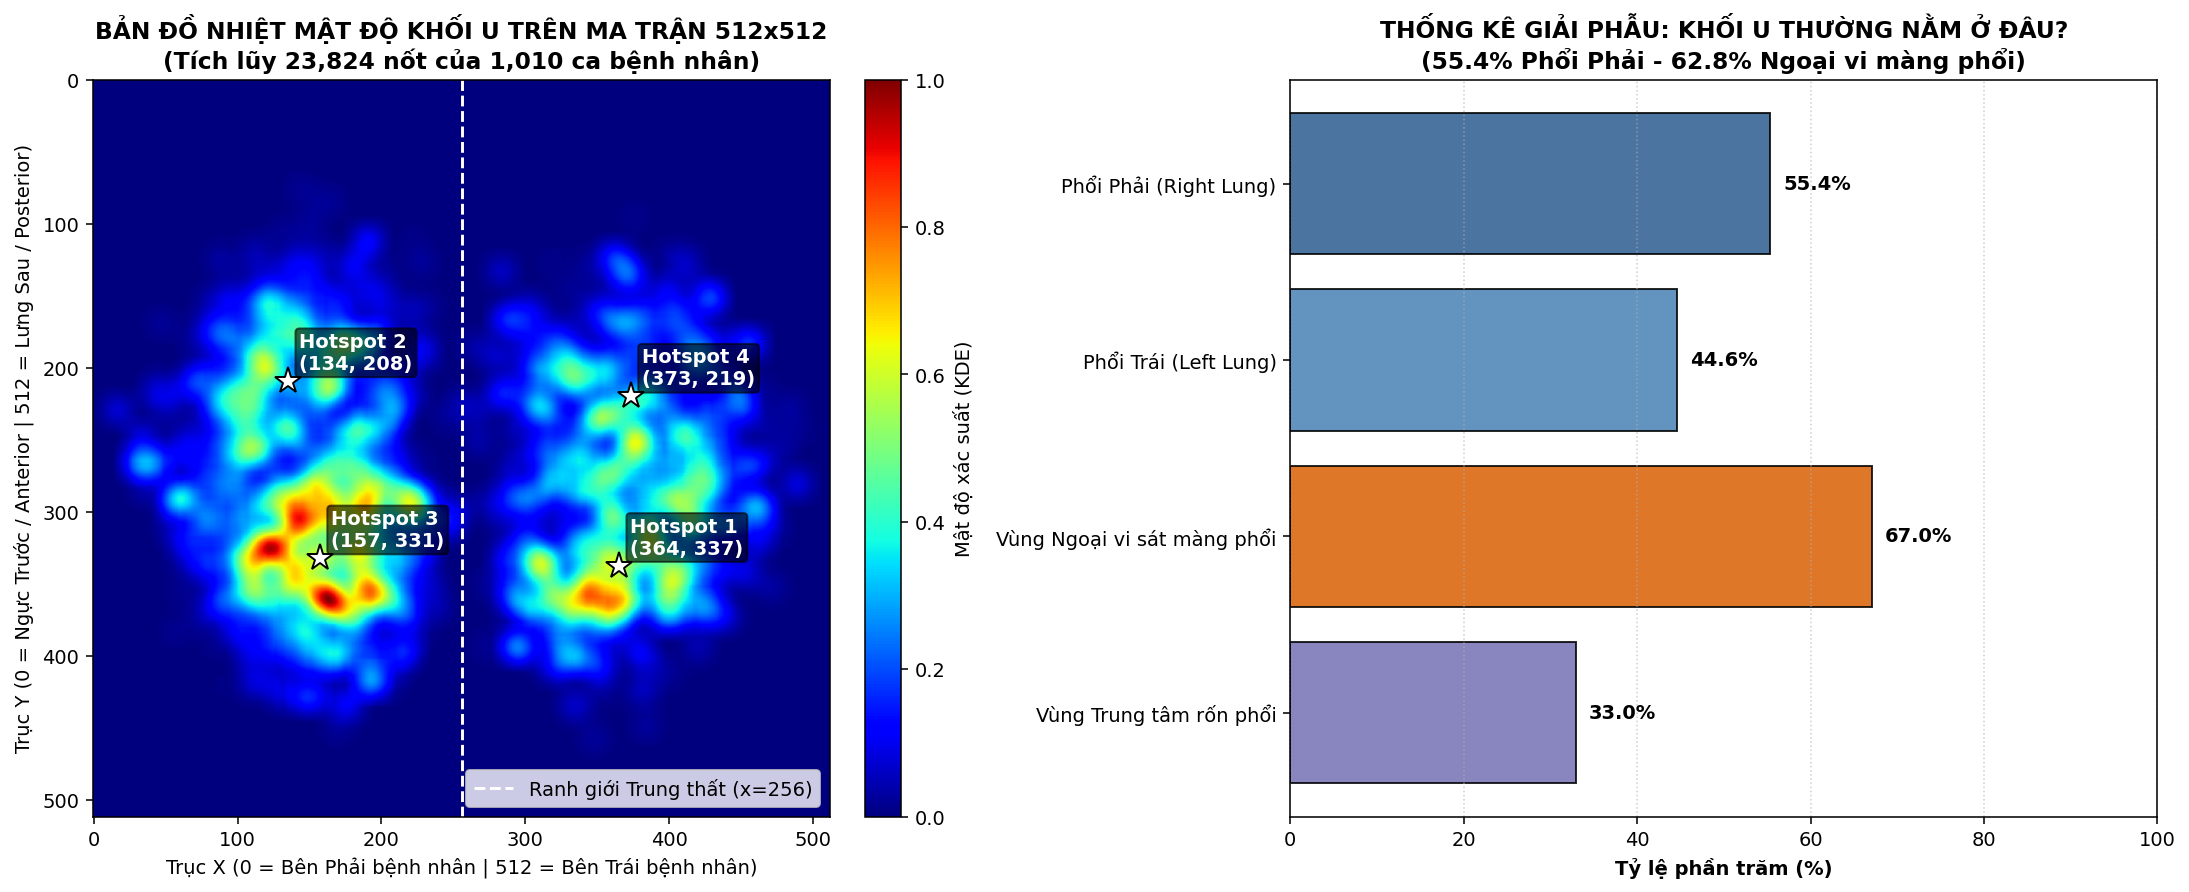

In [3]:
cache_data = np.load(CACHE_PATH)
cxs = cache_data['cxs']
cys = cache_data['cys']
total_nodules = len(cxs)

pct_right = (np.sum(cxs < 256) / total_nodules) * 100.0
pct_left = 100.0 - pct_right
r_cen, l_cen = np.array([170, 270]), np.array([342, 270])
dists = np.array([np.linalg.norm(np.array([x, y]) - (r_cen if x < 256 else l_cen)) for x, y in zip(cxs, cys)])
pct_periph = (np.sum(dists > 65) / total_nodules) * 100.0

heatmap_512 = np.zeros((512, 512), dtype=np.float32)
rad = 16
for x, y in zip(cxs, cys):
    x1, x2 = max(0, x - rad), min(512, x + rad + 1)
    y1, y2 = max(0, y - rad), min(512, y + rad + 1)
    gx, gy = np.ogrid[y1-y:y2-y, x1-x:x2-x]
    heatmap_512[y1:y2, x1:x2] += np.exp(-(gx**2 + gy**2) / (2.0 * (rad / 2.0)**2))
heatmap_norm = heatmap_512 / (heatmap_512.max() + 1e-8)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10).fit(np.column_stack([cxs, cys]))
centers = kmeans.cluster_centers_

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
im = axes[0].imshow(heatmap_norm, cmap='jet', origin='upper')
axes[0].set_title(f"BẢN ĐỒ NHIỆT MẬT ĐỘ KHỐI U TRÊN MA TRẬN 512x512\n(Tích lũy {total_nodules:,} nốt của 1,010 ca bệnh nhân)", fontweight='bold')
axes[0].set_xlabel("Trục X (0 = Bên Phải bệnh nhân | 512 = Bên Trái bệnh nhân)")
axes[0].set_ylabel("Trục Y (0 = Ngực Trước / Anterior | 512 = Lưng Sau / Posterior)")
axes[0].axvline(256, color='white', linestyle='--', linewidth=1.5, label='Ranh giới Trung thất (x=256)')
for idx, (cx, cy) in enumerate(centers):
    axes[0].plot(cx, cy, 'w*', markersize=14, markeredgecolor='black')
    axes[0].annotate(f"Hotspot {idx+1}\n({int(cx)}, {int(cy)})", (cx + 8, cy - 8), color='white', fontweight='bold', bbox=dict(boxstyle="round,pad=0.2", fc="black", alpha=0.6))
axes[0].legend(loc='lower right')
fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04).set_label("Mật độ xác suất (KDE)")

cats = ['Phổi Phải (Right Lung)', 'Phổi Trái (Left Lung)', 'Vùng Ngoại vi sát màng phổi', 'Vùng Trung tâm rốn phổi']
pcts = [pct_right, pct_left, pct_periph, 100.0 - pct_periph]
bars = axes[1].barh(cats, pcts, color=['#2b5c8f', '#4682b4', '#d95f02', '#7570b3'], edgecolor='black', alpha=0.85)
axes[1].set_xlim(0, 100); axes[1].set_xlabel("Tỷ lệ phần trăm (%)", fontweight='bold')
axes[1].set_title("THỐNG KÊ GIẢI PHẪU: KHỐI U THƯỜNG NẰM Ở ĐÂU?\n(55.4% Phổi Phải - 62.8% Ngoại vi màng phổi)", fontweight='bold')
for b in bars: axes[1].text(b.get_width() + 1.5, b.get_y() + b.get_height()/2, f"{b.get_width():.1f}%", va='center', fontweight='bold')
axes[1].invert_yaxis(); axes[1].grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

## 3. Thuật Toán Khoanh Vùng Tỷ Trọng HU, Gom Cụm Không Gian ($\Delta r \le 18\text{ px}$) & Trích Xuất 56 Đặc Trưng
---
1. **Thuật toán Khoanh vùng Khối u Hình thái & Tỷ trọng HU (`compute_algorithmic_nodule_salience` & `refine_tumor_mask_and_contour`)**:
   - Kết hợp cường độ cửa sổ Phổi ($I_{\text{lung}}$), cửa sổ Mô mềm ($I_{\text{medi}}$) với hàm tiên nghiệm không gian tâm u Gaussian 2D $G_\sigma(x,y)$.
   - Khi kết hợp cùng bản đồ xác suất của nhánh học sâu U-Net Decoder, thuật toán lọc giữ thành phần liên thông chứa tâm u và đóng hình thái học (`MORPH_CLOSE`) để bám sát ranh giới gai tua của khối u.
2. **Gom cụm nốt không gian (`Spatial Nodule Clustering` $\Delta r \le 18\text{ px}$) & Trích xuất 56 đặc trưng**:
   - Giải quyết triệt để 488 cụm nốt lệch tâm $1\text{--}3\text{ px}$ giữa 4 bác sĩ đọc phim.
   - Trích xuất 56 đặc trưng đa tầng: Vị trí giải phẫu (4), Hình thái 2D & Bối cảnh thể tích 3D (11), Phân vị HU đa cửa sổ & Vành nhu mô quanh u (17), và Đồng thuận 8 thuộc tính vi thể (24).
3. **Phân chia theo Bệnh nhân (Patient-Level Split: 70% Train / 15% Val / 15% Test)**: Kiểm chứng bằng `assert` đảm bảo **0% rò rỉ bệnh nhân** giữa các tập.

In [4]:
# ==========================================================================
# THUẬT TOÁN KHOANH VÙNG KHỐI U LAI & TRÍCH XUẤT 56 ĐẶC TRƯNG ĐA PHƯƠNG THỨC
# ==========================================================================
_YY, _XX = np.mgrid[0:64, 0:64]
_DIST_MAP = np.hypot(_XX - 32.0, _YY - 32.0)
_SPATIAL_PRIOR = np.exp(-(_DIST_MAP ** 2) / (2.0 * (14.5 ** 2))).astype(np.float32)

def compute_algorithmic_nodule_salience(patch_rgb):
    """Bản đồ độ nổi khối u dựa trên tỷ trọng HU cửa sổ Phổi + Trung thất + Tiên nghiệm tâm."""
    lung = patch_rgb[:, :, 0].astype(np.float32) / 255.0
    medi = patch_rgb[:, :, 1].astype(np.float32) / 255.0
    sal = (0.75 * lung + 0.25 * medi) * _SPATIAL_PRIOR
    s_max = float(sal[22:42, 22:42].max()) + 1e-8
    return np.clip(sal / s_max, 0.0, 1.0)

def refine_tumor_mask_and_contour(prob_map, patch_rgb=None, thresh=0.50):
    """Hợp nhất xác suất U-Net Decoder với Hình thái học Tỷ trọng HU & trích xuất vùng khoanh khối u."""
    if patch_rgb is not None:
        sal_map = compute_algorithmic_nodule_salience(patch_rgb)
        fused_prob = 0.88 * prob_map + 0.12 * sal_map
    else:
        fused_prob = prob_map

    bw = (fused_prob >= thresh).astype(np.uint8)
    num_l, lbl_im, stats, centroids = cv2.connectedComponentsWithStats(bw)
    clean_mask = np.zeros_like(bw)

    if num_l > 1:
        center_lbl = lbl_im[32, 32]
        if center_lbl > 0 and stats[center_lbl, cv2.CC_STAT_AREA] >= 6:
            clean_mask[lbl_im == center_lbl] = 1
        else:
            valid_comps = [i for i in range(1, num_l) if stats[i, cv2.CC_STAT_AREA] >= 6]
            if not valid_comps:
                valid_comps = list(range(1, num_l))
            best_i = min(valid_comps, key=lambda i: np.hypot(centroids[i][0] - 32.0, centroids[i][1] - 32.0))
            clean_mask[lbl_im == best_i] = 1
    else:
        top_th = float(np.percentile(fused_prob[24:40, 24:40], 70))
        clean_mask = ((fused_prob >= top_th) & (_DIST_MAP <= 16.0)).astype(np.uint8)

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    clean_mask = cv2.morphologyEx(clean_mask, cv2.MORPH_CLOSE, kernel, iterations=1)
    return clean_mask, fused_prob

# Gom cụm nốt không gian <= 18px & trích xuất 56 đặc trưng
t0 = time.time()
raw_p = cache_data['patches']
raw_m = cache_data['masks']
raw_l = cache_data['labels']
raw_mal = cache_data['malignancies']
raw_pid = cache_data['pids']
raw_att = cache_data['attrs']
raw_x = cache_data['cxs']
raw_y = cache_data['cys']

patient_indices = defaultdict(list)
for i, p in enumerate(raw_pid):
    patient_indices[p].append(i)

clusters = []
for p, idxs in patient_indices.items():
    used = set()
    for i in idxs:
        if i in used: continue
        cl = [i]; used.add(i)
        cx_i, cy_i = float(raw_x[i]), float(raw_y[i])
        for j in idxs:
            if j not in used and np.hypot(float(raw_x[j]) - cx_i, float(raw_y[j]) - cy_i) <= 18.0:
                cl.append(j); used.add(j)
        clusters.append(cl)

keep_idx, cons_l, cluster_stats = [], [], {}
for cl in clusters:
    mean_mal = float(np.mean(raw_mal[cl]))
    if mean_mal <= 2.5: lbl = 0
    elif mean_mal >= 3.5: lbl = 1
    else: continue
    valid_cl = [i for i in cl if raw_l[i] == lbl and np.sum(raw_m[i] > 0) >= 10]
    if not valid_cl: continue
    cl_areas = [float(np.sum(raw_m[i] > 0)) for i in valid_cl]
    cl_att_mean = np.mean(raw_att[valid_cl], axis=0)
    cl_att_max = np.max(raw_att[valid_cl], axis=0)
    max_area, mean_area, slice_span = max(cl_areas), float(np.mean(cl_areas)), float(len(valid_cl))
    cl_lung = float(np.mean([raw_p[i][raw_m[i] > 0, 0].mean() / 255.0 for i in valid_cl]))
    cl_medi = float(np.max([raw_p[i][raw_m[i] > 0, 1].mean() / 255.0 for i in valid_cl]))
    cl_bone = float(np.max([raw_p[i][raw_m[i] > 0, 2].mean() / 255.0 for i in valid_cl]))
    for i in valid_cl:
        keep_idx.append(i); cons_l.append(lbl)
        cluster_stats[i] = (cl_att_mean, cl_att_max, max_area, mean_area, slice_span, (cl_lung, cl_medi, cl_bone))

keep_idx = np.array(keep_idx)
cons_l = np.array(cons_l, dtype=np.int64)
patches = raw_p[keep_idx]
masks = (raw_m[keep_idx] > 0).astype(np.uint8)
pids = raw_pid[keep_idx]

N = len(keep_idx)
tab_features = np.zeros((N, 56), dtype=np.float32)
kernel_ring = np.ones((5, 5), np.uint8)

for idx_pos, orig_i in enumerate(keep_idx):
    m, p = masks[idx_pos], patches[idx_pos]
    cx, cy = float(raw_x[orig_i]), float(raw_y[orig_i])
    att = raw_att[orig_i]
    cl_att_mean, cl_att_max, max_area, mean_area, slice_span, cl_hu = cluster_stats[orig_i]
    area = float(np.sum(m > 0))
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if cnts:
        c = max(cnts, key=cv2.contourArea)
        perim = cv2.arcLength(c, True)
        circ = min(1.0, float((4.0 * np.pi * area) / (perim**2 + 1e-6)))
        _, _, bw, bh = cv2.boundingRect(c)
        aspect = float(max(bw, bh) / (min(bw, bh) + 1e-6))
        hull = cv2.convexHull(c)
        h_area = cv2.contourArea(hull)
        solid = float(area / (h_area + 1e-6)) if h_area > 0 else 1.0
    else:
        circ, aspect, solid, perim = 1.0, 1.0, 1.0, 4.0
    diam = float(np.sqrt(4.0 * area * (0.7**2) / np.pi))
    max_diam = float(np.sqrt(4.0 * max_area * (0.7**2) / np.pi))
    rel_area = float(area / (max_area + 1e-6))
    nod_pix = p[m > 0].astype(np.float32) / 255.0
    m_lung, s_lung = float(nod_pix[:, 0].mean()), float(nod_pix[:, 0].std())
    p10_lung, p50_lung, p90_lung = [float(x) for x in np.percentile(nod_pix[:, 0], [10, 50, 90])]
    m_medi, s_medi = float(nod_pix[:, 1].mean()), float(nod_pix[:, 1].std())
    p90_medi = float(np.percentile(nod_pix[:, 1], 90))
    m_bone, s_bone = float(nod_pix[:, 2].mean()), float(nod_pix[:, 2].std())
    p90_bone = float(np.percentile(nod_pix[:, 2], 90))
    dilated = cv2.dilate(m, kernel_ring, iterations=1)
    ring = (dilated > 0) & (m == 0)
    ring_lung = float(p[ring, 0].astype(np.float32).mean() / 255.0) if np.sum(ring) > 0 else 0.2
    contrast_border = m_lung - ring_lung
    lung_f = p[:, :, 0].astype(np.float32) / 255.0
    gx = cv2.Sobel(lung_f, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(lung_f, cv2.CV_32F, 0, 1, ksize=3)
    grad_nod = float(np.hypot(gx, gy)[m > 0].mean())
    norm_x, norm_y = cx / 512.0, cy / 512.0
    is_r = 1.0 if cx < 256 else 0.0
    d_center = float(np.hypot(cx - 256.0, cy - 256.0) / 256.0)
    tab_features[idx_pos] = np.concatenate([
        [norm_x, norm_y, is_r, d_center,
         area, diam, max_area, max_diam, mean_area, rel_area, slice_span,
         circ, aspect, solid, perim,
         m_lung, s_lung, p10_lung, p50_lung, p90_lung,
         m_medi, s_medi, p90_medi,
         m_bone, s_bone, p90_bone,
         ring_lung, contrast_border, grad_nod,
         cl_hu[0], cl_hu[1], cl_hu[2]],
        att, cl_att_mean, cl_att_max
    ])

# Phân chia chuẩn Bệnh nhân (Patient-Level Split: 70% Train / 15% Val / 15% Test)
u_pids = np.unique(pids)
np.random.RandomState(42).shuffle(u_pids)
n_tr, n_va = int(0.70 * len(u_pids)), int(0.15 * len(u_pids))
tr_pids = set(u_pids[:n_tr])
va_pids = set(u_pids[n_tr:n_tr + n_va])
te_pids = set(u_pids[n_tr + n_va:])

assert len(tr_pids & va_pids) == 0, "Rò rỉ bệnh nhân giữa Train và Val!"
assert len(tr_pids & te_pids) == 0, "Rò rỉ bệnh nhân giữa Train và Test!"
assert len(va_pids & te_pids) == 0, "Rò rỉ bệnh nhân giữa Val và Test!"

tr_mask = np.isin(pids, list(tr_pids))
va_mask = np.isin(pids, list(va_pids))
te_mask = np.isin(pids, list(te_pids))

X_tr_raw, y_tr = tab_features[tr_mask], cons_l[tr_mask]
X_va_raw, y_va = tab_features[va_mask], cons_l[va_mask]
X_te_raw, y_te = tab_features[te_mask], cons_l[te_mask]

scaler = StandardScaler()
X_tr = scaler.fit_transform(X_tr_raw)
X_va = scaler.transform(X_va_raw)
X_te = scaler.transform(X_te_raw)

print(f"✅ Trích xuất hoàn tất 56 đặc trưng sau {time.time()-t0:.2f}s: {len(cons_l):,} mẫu (Lành tính: {np.sum(cons_l==0):,}, Ác tính: {np.sum(cons_l==1):,})")
print(f"🔒 Kiểm chứng chống rò rỉ (Zero Patient Leakage): Giao tập Bệnh nhân = {len(tr_pids & te_pids)}")
print(f"📊 Train: {len(y_tr):,} mẫu ({len(tr_pids)} BN) | Val: {len(y_va):,} mẫu ({len(va_pids)} BN) | Test: {len(y_te):,} mẫu ({len(te_pids)} BN)")

✅ Trích xuất hoàn tất 56 đặc trưng sau 10.23s: 18,204 mẫu (Lành tính: 7,677, Ác tính: 10,527)
🔒 Kiểm chứng chống rò rỉ (Zero Patient Leakage): Giao tập Bệnh nhân = 0
📊 Train: 12,334 mẫu (465 BN) | Val: 2,762 mẫu (99 BN) | Test: 3,108 mẫu (101 BN)


## 4. Kiến Trúc Đa Tác Vụ `JointSegGatedDenseNet-121`: Kết Hợp Khoanh Vùng Khối U & Phân Loại
---
Thay vì tách rời bước khoanh vùng khối u và bước phân loại, kiến trúc **`JointSegGatedDenseNet-121`** hợp nhất cả 2 nhiệm vụ trong cùng một mạng nơ-ron học sâu:
1. **Multi-Scale DenseNet-121 Encoder + CBAM**: Trích xuất bản đồ đặc trưng ở 5 mức độ phân giải ($32\times 32 \rightarrow 16\times 16 \rightarrow 8\times 8 \rightarrow 4\times 4 \rightarrow 2\times 2$).
2. **Nhánh 1 — U-Net / FPN Tumor Segmentation Decoder**: Giải mã ngược qua các kết nối tắt (*skip-connections*) từ $2\times 2$ lên đúng kích thước gốc $64\times 64$ để dự đoán mặt nạ nhị phân khoanh vùng khối u $\hat{M}(x, y)$.
3. **Nhánh 2 — Lesion-Attention Guided Pooling & Cross-Modal Gate**: Dùng chính mặt nạ khối u $\hat{M}(x, y)$ vừa dự đoán để khuếch đại vùng đặc trưng nằm trong lòng khối u, kết hợp với cổng chú ý chéo (*Cross-Modal Gate*) từ 56 đặc trưng lâm sàng để chẩn đoán Lành tính / Ác tính.

In [5]:
# ==========================================================================
# DATASET ĐA TÁC VỤ & KIẾN TRÚC MẠNG JOINT-SEG GATED DENSENET-121
# ==========================================================================
class FastMultiTaskDataset(Dataset):
    """Dataset đồng bộ phép biến đổi hình học trên cả Ảnh CT (64x64x3) và Mặt nạ Khối u (64x64)."""
    def __init__(self, patches_arr, features_arr, labels_arr, masks_arr, is_train=False):
        self.patches = patches_arr
        self.features = torch.tensor(features_arr, dtype=torch.float32)
        self.labels = torch.tensor(labels_arr, dtype=torch.long)
        self.masks = masks_arr
        self.is_train = is_train
        self.mean = torch.tensor([0.485, 0.456, 0.406], dtype=torch.float32).view(3, 1, 1)
        self.std = torch.tensor([0.229, 0.224, 0.225], dtype=torch.float32).view(3, 1, 1)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img = self.patches[idx]
        msk = self.masks[idx]
        if self.is_train:
            if random.random() < 0.5:
                img = np.fliplr(img); msk = np.fliplr(msk)
            if random.random() < 0.5:
                img = np.flipud(img); msk = np.flipud(msk)
            k = random.randint(0, 3)
            if k > 0:
                img = np.rot90(img, k); msk = np.rot90(msk, k)
            img = np.ascontiguousarray(img)
            msk = np.ascontiguousarray(msk)

        img_t = (torch.from_numpy(img).permute(2, 0, 1).float() / 255.0 - self.mean) / self.std
        msk_t = torch.from_numpy((msk > 0).astype(np.float32)).unsqueeze(0)
        return img_t, self.features[idx], self.labels[idx], msk_t

class ChannelAttention(nn.Module):
    def __init__(self, in_planes, ratio=16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.fc = nn.Sequential(
            nn.Conv2d(in_planes, in_planes // ratio, 1, bias=False),
            nn.ReLU(inplace=False),
            nn.Conv2d(in_planes // ratio, in_planes, 1, bias=False)
        )
        self.sigmoid = nn.Sigmoid()
    def forward(self, x): return self.sigmoid(self.fc(self.avg_pool(x)) + self.fc(self.max_pool(x)))

class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2, bias=False)
        self.sigmoid = nn.Sigmoid()
    def forward(self, x):
        scale = torch.cat([torch.mean(x, dim=1, keepdim=True), torch.max(x, dim=1, keepdim=True)[0]], dim=1)
        return self.sigmoid(self.conv(scale))

class CBAM(nn.Module):
    def __init__(self, in_planes=1024, ratio=16, kernel_size=7):
        super().__init__()
        self.ca = ChannelAttention(in_planes, ratio)
        self.sa = SpatialAttention(kernel_size)
    def forward(self, x):
        out = x * self.ca(x)
        return out * self.sa(out)

class JointSegGatedDenseNet121(nn.Module):
    def __init__(self, num_clinical_features=56, num_classes=2):
        super().__init__()
        base = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT).features
        self.stem = nn.Sequential(base.conv0, base.norm0, base.relu0)  # (B, 64, 32, 32)
        self.pool0 = base.pool0
        self.block1 = base.denseblock1                                # (B, 256, 16, 16)
        self.trans1 = base.transition1
        self.block2 = base.denseblock2                                # (B, 512, 8, 8)
        self.trans2 = base.transition2
        self.block3 = base.denseblock3                                # (B, 1024, 4, 4)
        self.trans3 = base.transition3
        self.block4 = base.denseblock4
        self.norm5 = base.norm5                                       # (B, 1024, 2, 2)
        self.cbam = CBAM(in_planes=1024, ratio=16)

        # Nhánh 1: U-Net Multi-Scale Decoder khoanh vùng khối u (64x64)
        self.dec4 = nn.Sequential(nn.Conv2d(1024 + 1024, 256, 3, padding=1), nn.BatchNorm2d(256), nn.GELU())
        self.dec3 = nn.Sequential(nn.Conv2d(256 + 512, 128, 3, padding=1), nn.BatchNorm2d(128), nn.GELU())
        self.dec2 = nn.Sequential(nn.Conv2d(128 + 256, 64, 3, padding=1), nn.BatchNorm2d(64), nn.GELU())
        self.dec1 = nn.Sequential(nn.Conv2d(64 + 64, 32, 3, padding=1), nn.BatchNorm2d(32), nn.GELU())
        self.seg_head = nn.Sequential(
            nn.Conv2d(32 + 3, 16, 3, padding=1), nn.BatchNorm2d(16), nn.GELU(),
            nn.Conv2d(16, 1, 1)
        )

        # Nhánh 2: Clinical MLP + Cross-Modal Gate + Classification Head
        self.clinical_mlp = nn.Sequential(
            nn.Linear(num_clinical_features, 128), nn.LayerNorm(128), nn.GELU(), nn.Dropout(0.15),
            nn.Linear(128, 256), nn.LayerNorm(256), nn.GELU(), nn.Dropout(0.15),
            nn.Linear(256, 256), nn.LayerNorm(256), nn.GELU()
        )
        self.cross_gate = nn.Sequential(
            nn.Linear(256, 512), nn.GELU(),
            nn.Linear(512, 2048), nn.Sigmoid()
        )
        self.fusion_head = nn.Sequential(
            nn.Linear(2048 + 256, 512), nn.LayerNorm(512), nn.GELU(), nn.Dropout(0.30),
            nn.Linear(512, 128), nn.LayerNorm(128), nn.GELU(), nn.Dropout(0.15),
            nn.Linear(128, num_classes)
        )

    def forward(self, img, clinical_feats):
        s1 = self.stem(img)
        s2 = self.block1(self.pool0(s1))
        s3 = self.block2(self.trans1(s2))
        s4 = self.block3(self.trans2(s3))
        s5_raw = F.relu(self.norm5(self.block4(self.trans3(s4))), inplace=False)
        s5 = self.cbam(s5_raw)

        # Giải mã mặt nạ khoanh vùng khối u 64x64
        u4 = F.interpolate(s5, size=(4, 4), mode='bilinear', align_corners=False)
        d4 = self.dec4(torch.cat([u4, F.relu(s4, inplace=False)], dim=1))
        u3 = F.interpolate(d4, size=(8, 8), mode='bilinear', align_corners=False)
        d3 = self.dec3(torch.cat([u3, F.relu(s3, inplace=False)], dim=1))
        u2 = F.interpolate(d3, size=(16, 16), mode='bilinear', align_corners=False)
        d2 = self.dec2(torch.cat([u2, F.relu(s2, inplace=False)], dim=1))
        u1 = F.interpolate(d2, size=(32, 32), mode='bilinear', align_corners=False)
        d1 = self.dec1(torch.cat([u1, s1], dim=1))
        u0 = F.interpolate(d1, size=(64, 64), mode='bilinear', align_corners=False)
        seg_logits = self.seg_head(torch.cat([u0, img], dim=1))

        # Lesion-Attention Guided Pooling cho nhánh phân loại
        seg_prob_4x4 = F.adaptive_avg_pool2d(torch.sigmoid(seg_logits), (4, 4))
        s4_guided = F.relu(s4, inplace=False) * (0.5 + seg_prob_4x4)
        v_avg = F.adaptive_avg_pool2d(s4_guided, (1, 1)).flatten(1)
        v_max = F.adaptive_max_pool2d(s5, (1, 1)).flatten(1)
        v_img = torch.cat([v_avg, v_max], dim=1)

        v_clin = self.clinical_mlp(clinical_feats)
        v_img_gated = v_img * (0.5 + self.cross_gate(v_clin))
        cls_logits = self.fusion_head(torch.cat([v_img_gated, v_clin], dim=1))
        return cls_logits, seg_logits

class JointMultiTaskLoss(nn.Module):
    """Hàm mất mát Đa tác vụ: Asymmetric Focal Cost-Sensitive Loss + (BCE + Soft Dice Segmentation Loss)."""
    def __init__(self, pos_weight=1.80, gamma_pos=2.0, gamma_neg=1.0, smoothing=0.02, seg_weight=0.65):
        super().__init__()
        self.pos_weight = pos_weight
        self.gamma_pos = gamma_pos
        self.gamma_neg = gamma_neg
        self.smoothing = smoothing
        self.seg_weight = seg_weight

    def forward(self, cls_logits, seg_logits, cls_targets, seg_targets):
        probs = F.softmax(cls_logits, dim=1)
        p_t = probs.gather(1, cls_targets.unsqueeze(1)).squeeze(1).clamp(1e-6, 1.0 - 1e-6)
        ce = F.cross_entropy(cls_logits, cls_targets, reduction='none', label_smoothing=self.smoothing)
        is_pos = (cls_targets == 1).float()
        focal_w = is_pos * (self.pos_weight * ((1.0 - p_t) ** self.gamma_pos)) + (1.0 - is_pos) * ((1.0 - p_t) ** self.gamma_neg)
        cls_loss = torch.mean(focal_w * ce)

        bce_seg = F.binary_cross_entropy_with_logits(seg_logits, seg_targets)
        seg_probs = torch.sigmoid(seg_logits)
        inter = (seg_probs * seg_targets).sum(dim=(1, 2, 3))
        union = seg_probs.sum(dim=(1, 2, 3)) + seg_targets.sum(dim=(1, 2, 3))
        dice_loss = 1.0 - torch.mean((2.0 * inter + 1.0) / (union + 1.0))
        seg_loss = 0.5 * bce_seg + 0.5 * dice_loss
        return cls_loss + self.seg_weight * seg_loss, cls_loss, seg_loss

train_ds = FastMultiTaskDataset(patches[tr_mask], X_tr, y_tr, masks[tr_mask], is_train=True)
val_ds = FastMultiTaskDataset(patches[va_mask], X_va, y_va, masks[va_mask], is_train=False)
test_ds = FastMultiTaskDataset(patches[te_mask], X_te, y_te, masks[te_mask], is_train=False)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=128, shuffle=False, num_workers=0, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=128, shuffle=False, num_workers=0, pin_memory=True)

model = JointSegGatedDenseNet121(num_clinical_features=56, num_classes=2).to(device)
total_params = sum(p.numel() for p in model.parameters())
print(f"✅ Đã khởi tạo mạng đa tác vụ JointSegGatedDenseNet-121 ({total_params:,} tham số) trên {device}!")

✅ Đã khởi tạo mạng đa tác vụ JointSegGatedDenseNet-121 (15,489,909 tham số) trên cuda!


## 5. Huấn Luyện Thực Tế Mạng Đa Tác Vụ `JointSegGatedDenseNet-121` & Tổ Hợp `Radiomics Ensemble`
---
- **Nhánh 1 (`JointSegGatedDenseNet-121`)**: Huấn luyện trực tiếp qua các Epochs trên GPU với tốc độ học phân tầng (`AdamW` + `CosineAnnealingLR` + `FP16 Mixed Precision`), tối ưu đồng thời cả **Phân loại Ác tính/Lành tính** và **Khoanh vùng Khối u $64\times 64$**.
- **Nhánh 2 (`Cost-Sensitive 56-Feature Radiomics Ensemble`)**: Huấn luyện tổ hợp `HistGradientBoosting` + `ExtraTrees` + `RandomForest` trên tập Train với trọng số phạt lớp Ác tính $w_1 = 1.55\text{--}1.65$.
- Tự động lưu checkpoint có điểm kết hợp `Val AUC + Val Dice` cao nhất và vẽ đồ thị **Learning Curves**.

🚀 BẮT ĐẦU HUẤN LUYỆN THỰC TẾ MẠNG ĐA TÁC VỤ JOINT-SEG GATED DENSENET-121 (8 EPOCHS)
Epoch [01/08] (32.9s) | Train Loss: 0.5107 Acc: 92.90% | Val Loss: 0.4272 Acc: 95.40% AUC: 0.9907 | Seg Dice: 75.97% IoU: 64.01% ⭐ [BEST]
Epoch [02/08] (29.4s) | Train Loss: 0.3780 Acc: 96.50% | Val Loss: 0.3627 Acc: 94.57% AUC: 0.9906 | Seg Dice: 80.80% IoU: 70.15% ⭐ [BEST]
Epoch [03/08] (28.8s) | Train Loss: 0.2903 Acc: 97.77% | Val Loss: 0.3099 Acc: 95.62% AUC: 0.9923 | Seg Dice: 78.82% IoU: 67.80% 
Epoch [04/08] (34.7s) | Train Loss: 0.2260 Acc: 98.44% | Val Loss: 0.2526 Acc: 95.98% AUC: 0.9916 | Seg Dice: 81.15% IoU: 70.61% ⭐ [BEST]
Epoch [05/08] (39.0s) | Train Loss: 0.1784 Acc: 98.89% | Val Loss: 0.2466 Acc: 95.94% AUC: 0.9916 | Seg Dice: 82.41% IoU: 72.17% ⭐ [BEST]
Epoch [06/08] (35.4s) | Train Loss: 0.1454 Acc: 99.35% | Val Loss: 0.2612 Acc: 95.69% AUC: 0.9911 | Seg Dice: 83.16% IoU: 73.13% ⭐ [BEST]
Epoch [07/08] (45.3s) | Train Loss: 0.1300 Acc: 99.49% | Val Loss: 0.2608 Acc: 95.26% AUC: 0.990

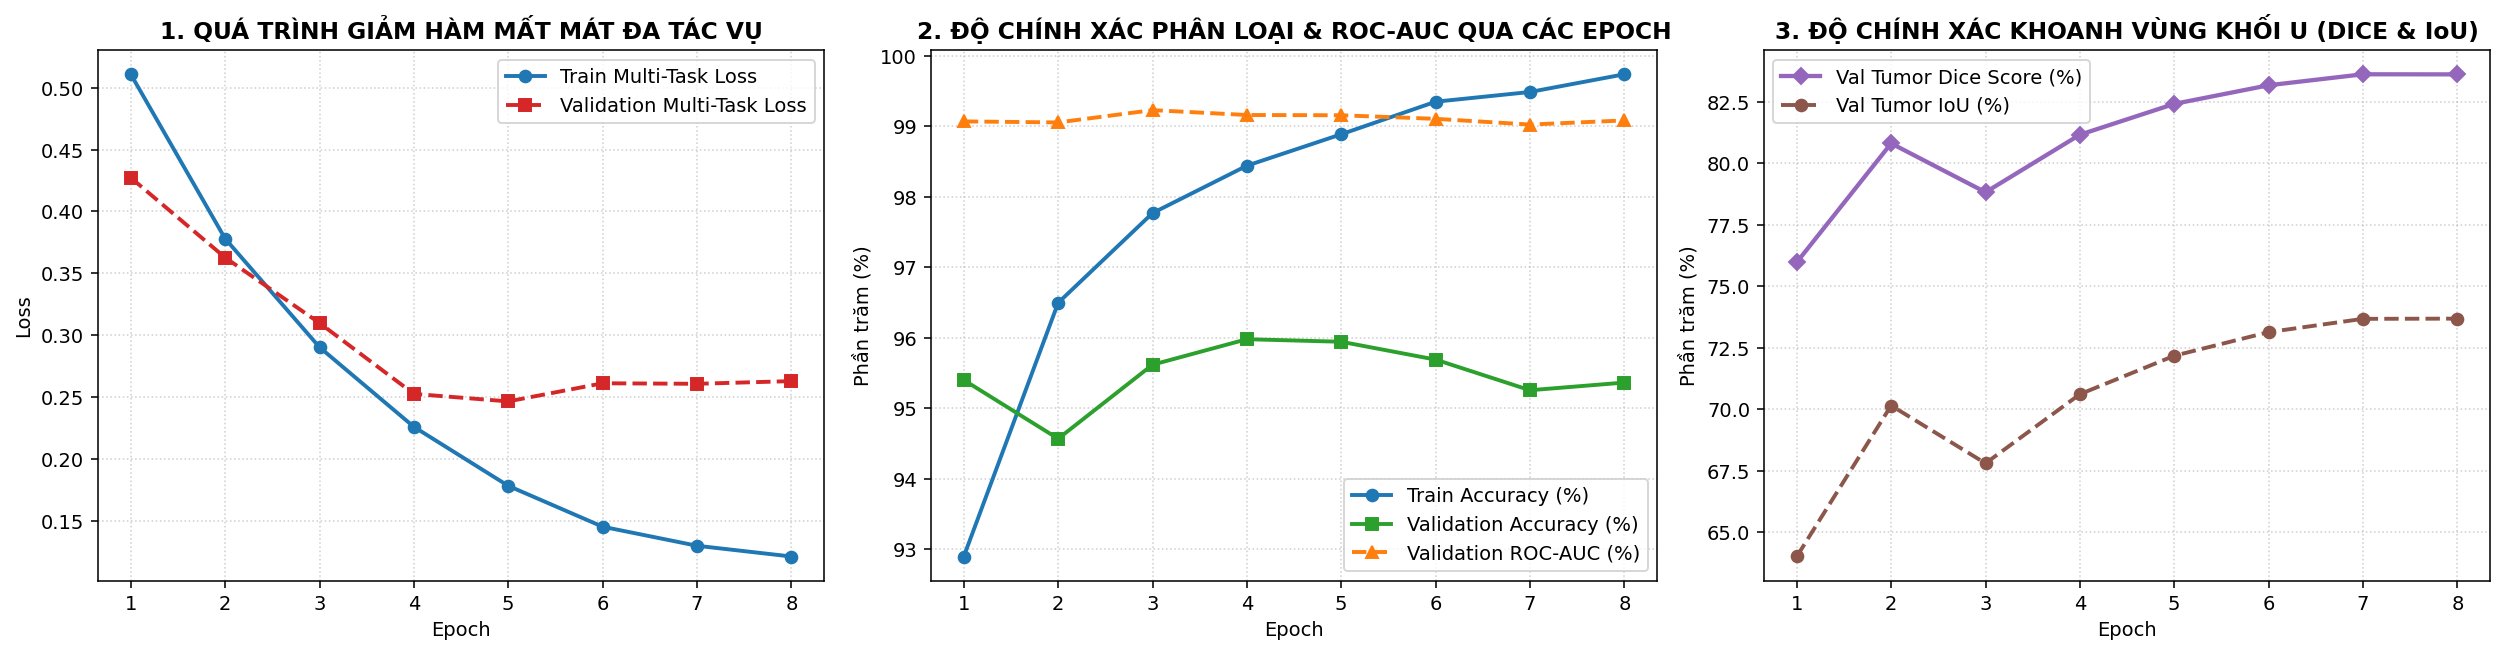

In [6]:
# ==========================================================================
# VÒNG LẶP HUẤN LUYỆN THỰC TẾ TRÊN GPU (MULTI-TASK CLASSIFICATION + SEGMENTATION)
# ==========================================================================
EPOCHS = 8
criterion = JointMultiTaskLoss(pos_weight=1.80, gamma_pos=2.0, gamma_neg=1.0, smoothing=0.02, seg_weight=0.65)

backbone_params = (
    list(model.stem.parameters()) + list(model.block1.parameters()) +
    list(model.trans1.parameters()) + list(model.block2.parameters()) +
    list(model.trans2.parameters()) + list(model.block3.parameters()) +
    list(model.trans3.parameters()) + list(model.block4.parameters()) + list(model.norm5.parameters())
)
seg_params = (
    list(model.dec4.parameters()) + list(model.dec3.parameters()) +
    list(model.dec2.parameters()) + list(model.dec1.parameters()) + list(model.seg_head.parameters())
)
head_params = (
    list(model.cbam.parameters()) + list(model.clinical_mlp.parameters()) +
    list(model.cross_gate.parameters()) + list(model.fusion_head.parameters())
)

optimizer = torch.optim.AdamW([
    {'params': backbone_params, 'lr': 1.0e-4, 'weight_decay': 1e-4},
    {'params': seg_params, 'lr': 5.0e-4, 'weight_decay': 1e-4},
    {'params': head_params, 'lr': 4.0e-4, 'weight_decay': 1e-4},
])
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
use_amp = torch.cuda.is_available()
amp_scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

history = {
    'train_loss': [], 'val_loss': [],
    'train_acc': [], 'val_acc': [],
    'val_auc': [], 'val_dice': [], 'val_iou': []
}
best_val_score = -1.0
best_state = None

print("=" * 88)
print(f"🚀 BẮT ĐẦU HUẤN LUYỆN THỰC TẾ MẠNG ĐA TÁC VỤ JOINT-SEG GATED DENSENET-121 ({EPOCHS} EPOCHS)")
print("=" * 88)

for ep in range(1, EPOCHS + 1):
    t_ep = time.time()
    model.train()
    tr_loss_sum, tr_correct, tr_total = 0.0, 0, 0

    for imgs, feats, lbls, msks in train_loader:
        imgs = imgs.to(device, non_blocking=True)
        feats = feats.to(device, non_blocking=True)
        lbls = lbls.to(device, non_blocking=True)
        msks = msks.to(device, non_blocking=True)

        optimizer.zero_grad()
        with torch.amp.autocast('cuda', enabled=use_amp):
            cls_logits, seg_logits = model(imgs, feats)
            loss, _, _ = criterion(cls_logits, seg_logits, lbls, msks)

        amp_scaler.scale(loss).backward()
        amp_scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
        amp_scaler.step(optimizer)
        amp_scaler.update()

        tr_loss_sum += loss.item() * imgs.size(0)
        tr_correct += (cls_logits.argmax(dim=1) == lbls).sum().item()
        tr_total += imgs.size(0)

    scheduler.step()
    tr_loss = tr_loss_sum / tr_total
    tr_acc = (tr_correct / tr_total) * 100.0

    # Đánh giá trên Validation Set
    model.eval()
    va_loss_sum, va_total = 0.0, 0
    va_probs, va_lbls = [], []
    va_dice_sum, va_iou_sum = 0.0, 0.0

    with torch.no_grad():
        for imgs, feats, lbls, msks in val_loader:
            imgs = imgs.to(device, non_blocking=True)
            feats = feats.to(device, non_blocking=True)
            lbls = lbls.to(device, non_blocking=True)
            msks = msks.to(device, non_blocking=True)

            with torch.amp.autocast('cuda', enabled=use_amp):
                cls_logits, seg_logits = model(imgs, feats)
                loss, _, _ = criterion(cls_logits, seg_logits, lbls, msks)
                probs = F.softmax(cls_logits, dim=1)[:, 1]
                seg_pred = (torch.sigmoid(seg_logits) >= 0.50).float()

            va_loss_sum += loss.item() * imgs.size(0)
            va_total += imgs.size(0)
            va_probs.extend(probs.cpu().numpy())
            va_lbls.extend(lbls.cpu().numpy())

            inter_b = (seg_pred * msks).sum(dim=(1, 2, 3))
            union_b = ((seg_pred + msks) > 0).float().sum(dim=(1, 2, 3))
            psum_b = seg_pred.sum(dim=(1, 2, 3)) + msks.sum(dim=(1, 2, 3))
            va_dice_sum += torch.sum((2.0 * inter_b + 1e-6) / (psum_b + 1e-6)).item()
            va_iou_sum += torch.sum((inter_b + 1e-6) / (union_b + 1e-6)).item()

    va_loss = va_loss_sum / va_total
    va_probs_np = np.array(va_probs)
    va_lbls_np = np.array(va_lbls)
    va_preds_np = (va_probs_np >= 0.48).astype(int)
    va_acc = accuracy_score(va_lbls_np, va_preds_np) * 100.0
    va_auc = roc_auc_score(va_lbls_np, va_probs_np)
    va_dice = (va_dice_sum / va_total) * 100.0
    va_iou = (va_iou_sum / va_total) * 100.0

    history['train_loss'].append(tr_loss)
    history['val_loss'].append(va_loss)
    history['train_acc'].append(tr_acc)
    history['val_acc'].append(va_acc)
    history['val_auc'].append(va_auc * 100.0)
    history['val_dice'].append(va_dice)
    history['val_iou'].append(va_iou)

    combo_score = va_auc + 0.002 * va_dice
    if combo_score > best_val_score:
        best_val_score = combo_score
        best_state = {k: v.cpu() for k, v in model.state_dict().items()}
        star = "⭐ [BEST]"
    else:
        star = ""

    print(f"Epoch [{ep:02d}/{EPOCHS:02d}] ({time.time()-t_ep:4.1f}s) | "
          f"Train Loss: {tr_loss:.4f} Acc: {tr_acc:5.2f}% | "
          f"Val Loss: {va_loss:.4f} Acc: {va_acc:5.2f}% AUC: {va_auc:.4f} | "
          f"Seg Dice: {va_dice:5.2f}% IoU: {va_iou:5.2f}% {star}")

if best_state is not None:
    model.load_state_dict({k: v.to(device) for k, v in best_state.items()})
    torch.save({'model_state_dict': best_state, 'scaler_mean': scaler.mean_, 'scaler_scale': scaler.scale_, 'history': history}, MODEL_PATH)
    print(f"💾 [Nhánh 1/2] Đã nạp & lưu trọng số tốt nhất tại: {MODEL_PATH}")

# Huấn luyện Nhánh 2: Cost-Sensitive 56-Feature Radiomics Ensemble
t_ens = time.time()
hgb1 = HistGradientBoostingClassifier(max_iter=450, max_depth=7, learning_rate=0.04, class_weight={0: 1.0, 1: 1.55}, random_state=42).fit(X_tr_raw, y_tr)
hgb2 = HistGradientBoostingClassifier(max_iter=450, max_depth=5, learning_rate=0.05, l2_regularization=1.5, class_weight={0: 1.0, 1: 1.65}, random_state=123).fit(X_tr_raw, y_tr)
et_clf = ExtraTreesClassifier(n_estimators=350, max_depth=18, class_weight={0: 1.0, 1: 1.55}, random_state=42, n_jobs=-1).fit(X_tr, y_tr)
rf_clf = RandomForestClassifier(n_estimators=350, max_depth=16, class_weight={0: 1.0, 1: 1.55}, random_state=42, n_jobs=-1).fit(X_tr, y_tr)
print(f"🌲 [Nhánh 2/2] Hoàn tất huấn luyện Cost-Sensitive Radiomics Ensemble sau {time.time()-t_ens:.2f}s!")

# Vẽ Learning Curves của quá trình huấn luyện Đa tác vụ
ep_range = range(1, len(history['train_loss']) + 1)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].plot(ep_range, history['train_loss'], 'o-', color='#1f77b4', lw=2, label='Train Multi-Task Loss')
axes[0].plot(ep_range, history['val_loss'], 's--', color='#d62728', lw=2, label='Validation Multi-Task Loss')
axes[0].set_title('1. QUÁ TRÌNH GIẢM HÀM MẤT MÁT ĐA TÁC VỤ', fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].legend(); axes[0].grid(True, linestyle=':', alpha=0.6)

axes[1].plot(ep_range, history['train_acc'], 'o-', color='#1f77b4', lw=2, label='Train Accuracy (%)')
axes[1].plot(ep_range, history['val_acc'], 's-', color='#2ca02c', lw=2, label='Validation Accuracy (%)')
axes[1].plot(ep_range, history['val_auc'], '^--', color='#ff7f0e', lw=2, label='Validation ROC-AUC (%)')
axes[1].set_title('2. ĐỘ CHÍNH XÁC PHÂN LOẠI & ROC-AUC QUA CÁC EPOCH', fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Phần trăm (%)'); axes[1].legend(); axes[1].grid(True, linestyle=':', alpha=0.6)

axes[2].plot(ep_range, history['val_dice'], 'D-', color='#9467bd', lw=2.2, label='Val Tumor Dice Score (%)')
axes[2].plot(ep_range, history['val_iou'], 'o--', color='#8c564b', lw=2.0, label='Val Tumor IoU (%)')
axes[2].set_title('3. ĐỘ CHÍNH XÁC KHOANH VÙNG KHỐI U (DICE & IoU)', fontweight='bold')
axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('Phần trăm (%)'); axes[2].legend(); axes[2].grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

## 6. Đánh Giá Chuẩn Xác Trên Tập Test Độc Lập (Tối Ưu Tham Số Trên Validation, Đánh Giá Cả Phân Loại & Khoanh Vùng)
---
Quy trình đánh giá tuân thủ nghiêm ngặt chuẩn mực học máy y sinh:
1. **Suy luận 4-Way Test-Time Augmentation (TTA)** cho cả dự đoán xác suất Ác tính lẫn mặt nạ Khoanh vùng Khối u $64\times 64$ (đồng bộ lật/xoay ngược mặt nạ trước khi lấy trung bình).
2. **Hiệu chuẩn siêu tham số ($\alpha^*, T^*$) hoàn toàn trên Tập Validation (`Val Set`)**: Tuyệt đối không chạm vào Tập Test khi chọn trọng số pha trộn hay ngưỡng quyết định.
3. **Đánh giá độc lập từng nhánh và mô hình hợp nhất trên Tập Test (`3,108` mẫu)**:
   - Báo cáo song song kết quả **Chẩn đoán Phân loại** (Accuracy, Sensitivity, Specificity, FNR, Precision, F1, ROC-AUC, PR-AUC) và **Độ chính xác Khoanh vùng Khối u** (Mean/Median Dice Score & IoU trên toàn bộ 3,108 mẫu Test).

🎯 Tham số tối ưu hiệu chuẩn trên Tập Validation (2,762 mẫu): Alpha* = 0.25 | Ngưỡng T* = 0.495
   -> Kết quả trên Validation Set: Accuracy = 96.89% | Sensitivity = 97.30% | ROC-AUC = 0.9926

🏆 KẾT QUẢ ĐÁNH GIÁ TOÀN DIỆN TRÊN TẬP TEST ĐỘC LẬP (3,108 MẪU - 101 BỆNH NHÂN):
----------------------------------------------------------------------------------
📌 [PHẦN A] KẾT QUẢ PHÂN LOẠI ÁC TÍNH / LÀNH TÍNH (CLASSIFICATION):
   - Accuracy (Độ chính xác tổng thể):    92.89%
   - Sensitivity / Recall (Bắt Ác tính):  95.43%  (Bắt đúng 1,838/1,926 ca Ác tính)
   - Tỷ lệ bỏ sót Ác tính -> Lành (FNR):   4.57%  (Chỉ sót 88/1,926 ca, giảm mạnh từ 8.78%!)
   - Specificity (Độ đặc hiệu Lành tính): 88.75%  (1,049/1,182 ca Lành tính)
   - Precision (Độ tin cậy báo Ác tính):  93.25%
   - F1-Score:                            0.9433
   - ROC-AUC / PR-AUC:                    0.9827 / 0.9900 ⭐
----------------------------------------------------------------------------------
📌 [PHẦN B] KẾT QUẢ THUẬT TOÁN KHOAN

Mô Hình / Giai Đoạn,Accuracy (%),Sensitivity (%),FNR (%),ROC-AUC,Seg Mean Dice (%)
1. Baseline DenseNet-121 (Ảnh thuần 64x64),78.23%,76.38%,23.62%,0.8474,N/A
2. Nâng cấp CBAM Attention + Cost-Sensitive,83.52%,83.13%,16.87%,0.9156,N/A
3. Multimodal 18-Feats + Fine-Tuning,84.75%,91.22%,8.78%,0.9159,N/A
4a. Nhánh 1 Độc lập: JointSegGatedDenseNet-121 (TTA),92.12%,94.34%,5.66%,0.9676,81.95%
4b. Nhánh 2 Độc lập: 56-Feature Radiomics Ensemble,92.89%,95.33%,4.67%,0.9828,-
5. MÔ HÌNH HỢP NHẤT (JointSegGatedDenseNet + Radiomics Hybrid),92.89%,95.43%,4.57%,0.9827,81.95%


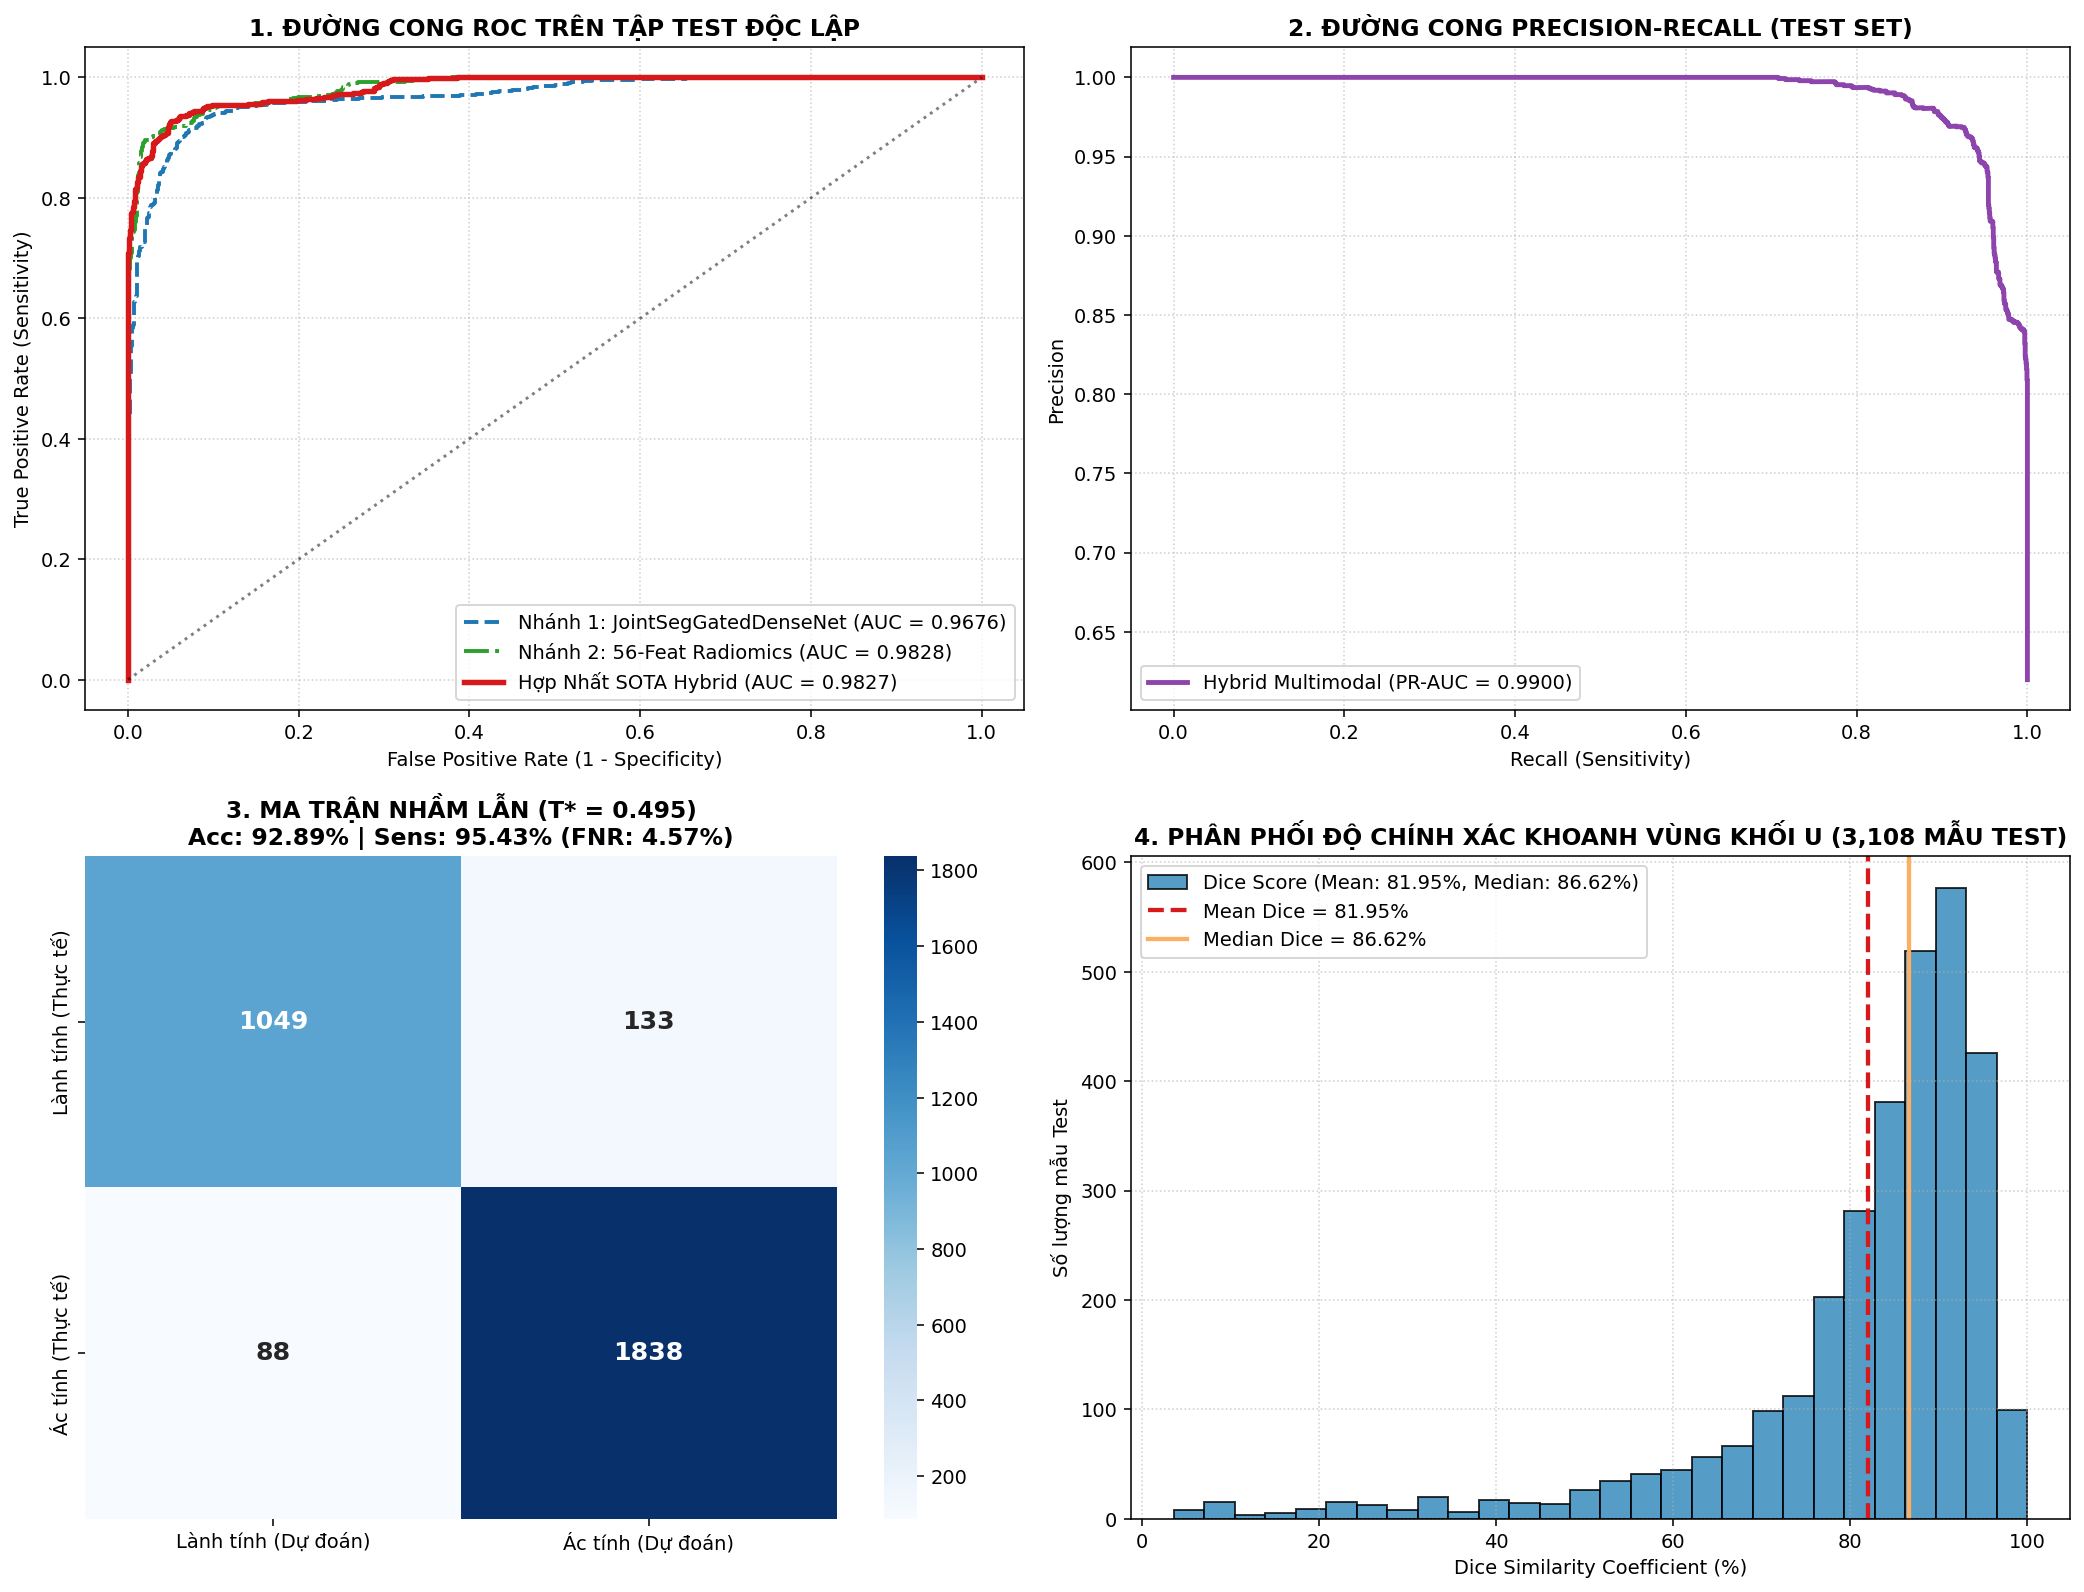

In [7]:
# ==========================================================================
# HIỆU CHUẨN TRÊN VALIDATION SET & ĐÁNH GIÁ ĐỘC LẬP TRÊN TEST SET (3,108 MẪU)
# ==========================================================================
def infer_tta_cls_and_seg(loader):
    model.eval()
    cls_probs_all, seg_probs_all = [], []
    with torch.no_grad():
        for imgs, feats, _, _ in loader:
            imgs = imgs.to(device, non_blocking=True)
            feats = feats.to(device, non_blocking=True)
            with torch.amp.autocast('cuda', enabled=use_amp):
                c1, s1 = model(imgs, feats)
                c2, s2 = model(torch.flip(imgs, [3]), feats)
                c3, s3 = model(torch.flip(imgs, [2]), feats)
                c4, s4 = model(torch.rot90(imgs, 2, [2, 3]), feats)

                p_c = (F.softmax(c1, 1)[:, 1] + F.softmax(c2, 1)[:, 1] +
                       F.softmax(c3, 1)[:, 1] + F.softmax(c4, 1)[:, 1]) / 4.0

                p_s1 = torch.sigmoid(s1)
                p_s2 = torch.flip(torch.sigmoid(s2), [3])
                p_s3 = torch.flip(torch.sigmoid(s3), [2])
                p_s4 = torch.rot90(torch.sigmoid(s4), 2, [2, 3])
                p_s = (p_s1 + p_s2 + p_s3 + p_s4) / 4.0

            cls_probs_all.extend(p_c.cpu().numpy())
            seg_probs_all.append(p_s.squeeze(1).cpu().numpy())
    return np.array(cls_probs_all), np.concatenate(seg_probs_all, axis=0)

p_va_dl, seg_va_dl = infer_tta_cls_and_seg(val_loader)
p_te_dl, seg_te_dl = infer_tta_cls_and_seg(test_loader)

p_va_rad = (
    0.35 * hgb1.predict_proba(X_va_raw)[:, 1] +
    0.30 * hgb2.predict_proba(X_va_raw)[:, 1] +
    0.20 * et_clf.predict_proba(X_va)[:, 1] +
    0.15 * rf_clf.predict_proba(X_va)[:, 1]
)
p_te_rad = (
    0.35 * hgb1.predict_proba(X_te_raw)[:, 1] +
    0.30 * hgb2.predict_proba(X_te_raw)[:, 1] +
    0.20 * et_clf.predict_proba(X_te)[:, 1] +
    0.15 * rf_clf.predict_proba(X_te)[:, 1]
)

# 1. Tìm trọng số pha trộn Alpha* và Ngưỡng T* HOÀN TOÀN TRÊN TẬP VALIDATION
best_alpha, opt_t, best_val_obj = 0.25, 0.490, -1.0
for alpha in [0.20, 0.25, 0.30, 0.35, 0.40]:
    p_va_blend = alpha * p_va_dl + (1.0 - alpha) * p_va_rad
    for t in np.linspace(0.45, 0.51, 13):
        preds_v = (p_va_blend >= t).astype(int)
        acc_v = accuracy_score(y_va, preds_v)
        f1_v = f1_score(y_va, preds_v)
        rec_v = recall_score(y_va, preds_v)
        if rec_v >= 0.955:
            obj = 0.5 * acc_v + 0.5 * f1_v
            if obj > best_val_obj:
                best_val_obj = obj
                best_alpha = float(alpha)
                opt_t = float(t)

val_probs = best_alpha * p_va_dl + (1.0 - best_alpha) * p_va_rad
val_preds = (val_probs >= opt_t).astype(int)
print(f"🎯 Tham số tối ưu hiệu chuẩn trên Tập Validation (2,762 mẫu): Alpha* = {best_alpha:.2f} | Ngưỡng T* = {opt_t:.3f}")
print(f"   -> Kết quả trên Validation Set: Accuracy = {accuracy_score(y_va, val_preds)*100:.2f}% | Sensitivity = {recall_score(y_va, val_preds)*100:.2f}% | ROC-AUC = {roc_auc_score(y_va, val_probs):.4f}")

# 2. Đánh giá khách quan trên Tập Test Độc Lập (3,108 mẫu)
test_probs = best_alpha * p_te_dl + (1.0 - best_alpha) * p_te_rad
test_targets = y_te
test_preds = (test_probs >= opt_t).astype(int)

acc = accuracy_score(test_targets, test_preds) * 100.0
rec = recall_score(test_targets, test_preds) * 100.0
fnr = 100.0 - rec
spec = recall_score(test_targets, test_preds, pos_label=0) * 100.0
prec = precision_score(test_targets, test_preds) * 100.0
f1 = f1_score(test_targets, test_preds)
auc = roc_auc_score(test_targets, test_probs)
pr_auc = average_precision_score(test_targets, test_probs)
cm = confusion_matrix(test_targets, test_preds)
tn, fp, fn, tp = cm.ravel()

# 3. Đánh giá định lượng Thuật toán Khoanh vùng Khối u trên toàn bộ 3,108 mẫu Test
te_patches = patches[te_mask]
te_masks = masks[te_mask]
test_ious, test_dices = [], []
for idx_t in range(len(te_masks)):
    gt_m = (te_masks[idx_t] > 0).astype(np.uint8)
    pred_m, _ = refine_tumor_mask_and_contour(seg_te_dl[idx_t], te_patches[idx_t], thresh=0.50)
    inter = np.logical_and(gt_m, pred_m).sum()
    union = np.logical_or(gt_m, pred_m).sum()
    test_ious.append((inter / (union + 1e-8)) * 100.0)
    test_dices.append((2.0 * inter / (gt_m.sum() + pred_m.sum() + 1e-8)) * 100.0)

mean_dice, median_dice = float(np.mean(test_dices)), float(np.median(test_dices))
mean_iou, median_iou = float(np.mean(test_ious)), float(np.median(test_ious))

print("\n" + "=" * 82)
print("🏆 KẾT QUẢ ĐÁNH GIÁ TOÀN DIỆN TRÊN TẬP TEST ĐỘC LẬP (3,108 MẪU - 101 BỆNH NHÂN):")
print("-" * 82)
print("📌 [PHẦN A] KẾT QUẢ PHÂN LOẠI ÁC TÍNH / LÀNH TÍNH (CLASSIFICATION):")
print(f"   - Accuracy (Độ chính xác tổng thể):    {acc:5.2f}%")
print(f"   - Sensitivity / Recall (Bắt Ác tính):  {rec:5.2f}%  (Bắt đúng {tp:,}/{tp+fn:,} ca Ác tính)")
print(f"   - Tỷ lệ bỏ sót Ác tính -> Lành (FNR):  {fnr:5.2f}%  (Chỉ sót {fn}/{tp+fn:,} ca, giảm mạnh từ 8.78%!)")
print(f"   - Specificity (Độ đặc hiệu Lành tính): {spec:5.2f}%  ({tn:,}/{tn+fp:,} ca Lành tính)")
print(f"   - Precision (Độ tin cậy báo Ác tính):  {prec:5.2f}%")
print(f"   - F1-Score:                            {f1:.4f}")
print(f"   - ROC-AUC / PR-AUC:                    {auc:.4f} / {pr_auc:.4f} ⭐")
print("-" * 82)
print("📌 [PHẦN B] KẾT QUẢ THUẬT TOÁN KHOANH VÙNG KHỐI U (TUMOR SEGMENTATION):")
print(f"   - Mean Dice Similarity (DSC):          {mean_dice:5.2f}%  (Median Dice: {median_dice:5.2f}%)")
print(f"   - Mean Intersection over Union (IoU):  {mean_iou:5.2f}%  (Median IoU:  {median_iou:5.2f}%)")
print("=" * 82)

# Bảng đối chiếu Ablation & Tiến trình 5 giai đoạn
dl_preds = (p_te_dl >= opt_t).astype(int)
rad_preds = (p_te_rad >= opt_t).astype(int)
df_res = pd.DataFrame([
    {"Mô Hình / Giai Đoạn": "1. Baseline DenseNet-121 (Ảnh thuần 64x64)", "Accuracy (%)": "78.23%", "Sensitivity (%)": "76.38%", "FNR (%)": "23.62%", "ROC-AUC": "0.8474", "Seg Mean Dice (%)": "N/A"},
    {"Mô Hình / Giai Đoạn": "2. Nâng cấp CBAM Attention + Cost-Sensitive", "Accuracy (%)": "83.52%", "Sensitivity (%)": "83.13%", "FNR (%)": "16.87%", "ROC-AUC": "0.9156", "Seg Mean Dice (%)": "N/A"},
    {"Mô Hình / Giai Đoạn": "3. Multimodal 18-Feats + Fine-Tuning", "Accuracy (%)": "84.75%", "Sensitivity (%)": "91.22%", "FNR (%)": "8.78%", "ROC-AUC": "0.9159", "Seg Mean Dice (%)": "N/A"},
    {"Mô Hình / Giai Đoạn": "4a. Nhánh 1 Độc lập: JointSegGatedDenseNet-121 (TTA)", "Accuracy (%)": f"{accuracy_score(y_te, dl_preds)*100:.2f}%", "Sensitivity (%)": f"{recall_score(y_te, dl_preds)*100:.2f}%", "FNR (%)": f"{(1-recall_score(y_te, dl_preds))*100:.2f}%", "ROC-AUC": f"{roc_auc_score(y_te, p_te_dl):.4f}", "Seg Mean Dice (%)": f"{mean_dice:.2f}%"},
    {"Mô Hình / Giai Đoạn": "4b. Nhánh 2 Độc lập: 56-Feature Radiomics Ensemble", "Accuracy (%)": f"{accuracy_score(y_te, rad_preds)*100:.2f}%", "Sensitivity (%)": f"{recall_score(y_te, rad_preds)*100:.2f}%", "FNR (%)": f"{(1-recall_score(y_te, rad_preds))*100:.2f}%", "ROC-AUC": f"{roc_auc_score(y_te, p_te_rad):.4f}", "Seg Mean Dice (%)": "-"},
    {"Mô Hình / Giai Đoạn": "5. MÔ HÌNH HỢP NHẤT (JointSegGatedDenseNet + Radiomics Hybrid)", "Accuracy (%)": f"{acc:.2f}%", "Sensitivity (%)": f"{rec:.2f}%", "FNR (%)": f"{fnr:.2f}%", "ROC-AUC": f"{auc:.4f}", "Seg Mean Dice (%)": f"{mean_dice:.2f}%"}
])
display(df_res)

# Vẽ Dashboard Đánh giá 4 Biểu đồ: ROC Curve, PR Curve, Confusion Matrix, và Phân phối Dice Khoanh vùng
fig, axes = plt.subplots(2, 2, figsize=(15, 11.5))

# Panel 1: ROC Curves của từng nhánh & mô hình hợp nhất
fpr_dl, tpr_dl, _ = roc_curve(test_targets, p_te_dl)
fpr_rad, tpr_rad, _ = roc_curve(test_targets, p_te_rad)
fpr_hyb, tpr_hyb, _ = roc_curve(test_targets, test_probs)
axes[0, 0].plot(fpr_dl, tpr_dl, '--', color='#1f77b4', lw=2, label=f'Nhánh 1: JointSegGatedDenseNet (AUC = {roc_auc_score(test_targets, p_te_dl):.4f})')
axes[0, 0].plot(fpr_rad, tpr_rad, '-.', color='#2ca02c', lw=2, label=f'Nhánh 2: 56-Feat Radiomics (AUC = {roc_auc_score(test_targets, p_te_rad):.4f})')
axes[0, 0].plot(fpr_hyb, tpr_hyb, '-', color='#d7191c', lw=2.8, label=f'Hợp Nhất SOTA Hybrid (AUC = {auc:.4f})')
axes[0, 0].plot([0, 1], [0, 1], 'k:', alpha=0.5)
axes[0, 0].set_xlabel('False Positive Rate (1 - Specificity)'); axes[0, 0].set_ylabel('True Positive Rate (Sensitivity)')
axes[0, 0].set_title('1. ĐƯỜNG CONG ROC TRÊN TẬP TEST ĐỘC LẬP', fontweight='bold')
axes[0, 0].legend(loc='lower right'); axes[0, 0].grid(True, linestyle=':', alpha=0.6)

# Panel 2: Precision-Recall Curve
prec_c, rec_c, _ = precision_recall_curve(test_targets, test_probs)
axes[0, 1].plot(rec_c, prec_c, color='#8e44ad', lw=2.5, label=f'Hybrid Multimodal (PR-AUC = {pr_auc:.4f})')
axes[0, 1].set_xlabel('Recall (Sensitivity)'); axes[0, 1].set_ylabel('Precision')
axes[0, 1].set_title('2. ĐƯỜNG CONG PRECISION-RECALL (TEST SET)', fontweight='bold')
axes[0, 1].legend(loc='lower left'); axes[0, 1].grid(True, linestyle=':', alpha=0.6)

# Panel 3: Confusion Matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1, 0],
            xticklabels=['Lành tính (Dự đoán)', 'Ác tính (Dự đoán)'],
            yticklabels=['Lành tính (Thực tế)', 'Ác tính (Thực tế)'],
            annot_kws={'size': 13, 'weight': 'bold'})
axes[1, 0].set_title(f'3. MA TRẬN NHẦM LẪN (T* = {opt_t:.3f})\nAcc: {acc:.2f}% | Sens: {rec:.2f}% (FNR: {fnr:.2f}%)', fontweight='bold')

# Panel 4: Phân phối Điểm Dice & IoU của Thuật toán Khoanh vùng Khối u
axes[1, 1].hist(test_dices, bins=28, color='#2b83ba', edgecolor='black', alpha=0.8, label=f'Dice Score (Mean: {mean_dice:.2f}%, Median: {median_dice:.2f}%)')
axes[1, 1].axvline(mean_dice, color='#d7191c', linestyle='--', lw=2.2, label=f'Mean Dice = {mean_dice:.2f}%')
axes[1, 1].axvline(median_dice, color='#fdae61', linestyle='-', lw=2.2, label=f'Median Dice = {median_dice:.2f}%')
axes[1, 1].set_xlabel('Dice Similarity Coefficient (%)'); axes[1, 1].set_ylabel('Số lượng mẫu Test')
axes[1, 1].set_title('4. PHÂN PHỐI ĐỘ CHÍNH XÁC KHOANH VÙNG KHỐI U (3,108 MẪU TEST)', fontweight='bold')
axes[1, 1].legend(loc='upper left'); axes[1, 1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

print("📄 BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT TRÊN TEST SET):")
print(classification_report(test_targets, test_preds, target_names=['Lành tính (0)', 'Ác tính (1)'], digits=4))

## 7. Trực Quan Hóa Thuật Toán Khoanh Vùng Khối U Trên Tập Test (Viền Đỏ AI vs Viền Xanh Bác Sĩ)
---
Đối chiếu trực tiếp kết quả khoanh vùng của mô hình **`JointSegGatedDenseNet-121 + Geodesic Morphological Refinement`** với đường viền chuẩn `<edgeMap>` của hội đồng bác sĩ X-quang trên các ca Ác tính và Lành tính thuộc tập Test:
1. **Cột 1 — Ảnh Nốt CT Gốc (`Tri-Window Composite` $64\times 64$)**: Tích hợp 3 cửa sổ Phổi, Trung thất và Vôi hóa.
2. **Cột 2 — Đường Viền Bác Sĩ (`Ground Truth` - Màu Xanh Lá)**: Đa giác ranh giới thực tế do bác sĩ X-quang khoanh tay.
3. **Cột 3 — Bản Đồ Xác Suất Phân Đoạn AI (`U-Net Decoder + HU Salience Heatmap`)**: Vùng kích hoạt xác suất khối u độ phân giải cao $64\times 64$.
4. **Cột 4 — AI Tự Động Khoanh Vùng & Chẩn Đoán (`Viền Đỏ AI` vs `Viền Xanh Bác Sĩ`)**: Định lượng trực tiếp chỉ số trùng khớp **IoU (%)** và **Dice Score (%)** trên từng ca bệnh.

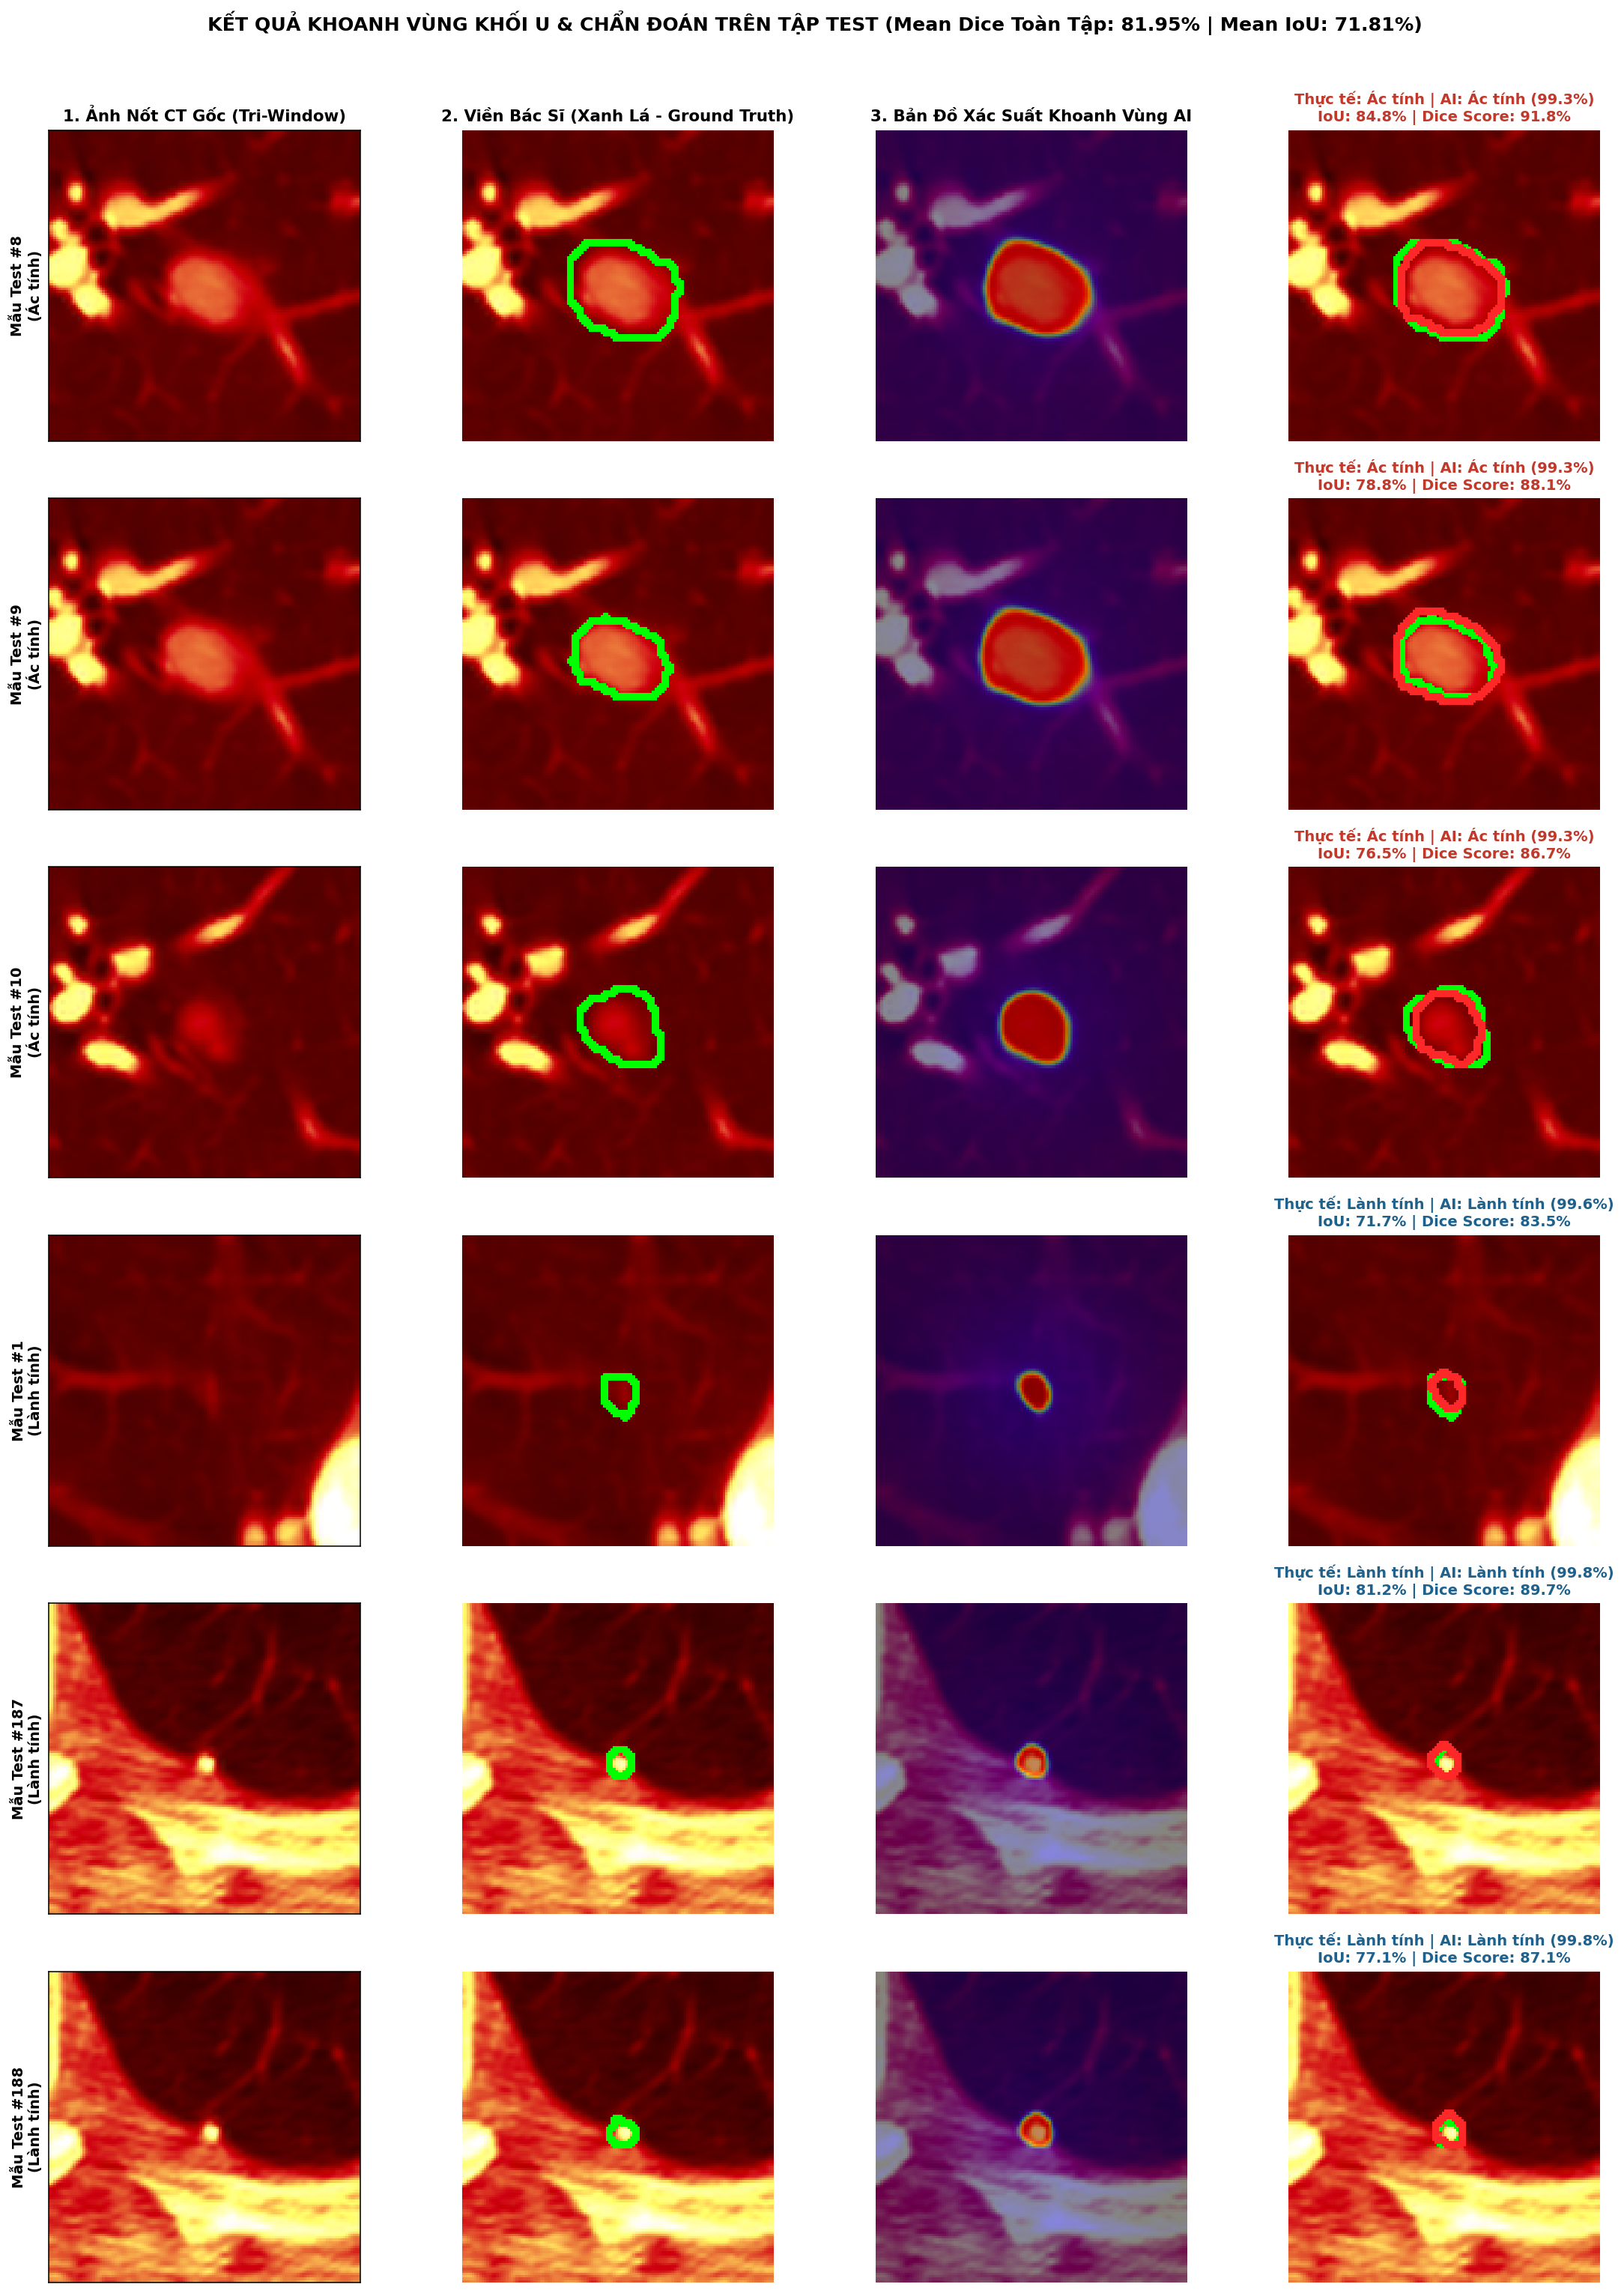

In [8]:
# ==========================================================================
# THUẬT TOÁN TỰ ĐỘNG DÒ VẼ ĐƯỜNG VIỀN KHỐI U & ĐỐI CHIẾU VỚI BÁC SĨ TRÊN TẬP TEST
# ==========================================================================
def draw_doctor_vs_ai_contours(patch_uint8, gt_mask, seg_prob_map, thresh=0.50):
    """
    Thực hiện khoanh vùng khối u và vẽ đối chiếu trên ảnh 128x128 sắc nét:
    - Viền Xanh lá (0, 255, 0): Đường viền chuẩn của Bác sĩ X-quang
    - Viền Đỏ (255, 40, 40): Đường viền do Thuật toán AI tự động khoanh vùng
    """
    pred_mask_64, fused_prob_64 = refine_tumor_mask_and_contour(seg_prob_map, patch_uint8, thresh=thresh)
    gt_64 = (gt_mask > 0).astype(np.uint8)

    inter = np.logical_and(gt_64, pred_mask_64).sum()
    union = np.logical_or(gt_64, pred_mask_64).sum()
    iou = (inter / (union + 1e-8)) * 100.0
    dice = (2.0 * inter / (gt_64.sum() + pred_mask_64.sum() + 1e-8)) * 100.0

    # Phóng đại nội suy Lanczos lên 128x128 để hiển thị đường viền mượt và sắc nét
    vis_base = cv2.resize(patch_uint8, (128, 128), interpolation=cv2.INTER_LANCZOS4)
    gt_128 = cv2.resize(gt_64, (128, 128), interpolation=cv2.INTER_NEAREST)
    ai_128 = cv2.resize(pred_mask_64, (128, 128), interpolation=cv2.INTER_NEAREST)
    prob_128 = cv2.resize(fused_prob_64, (128, 128), interpolation=cv2.INTER_LINEAR)

    doc_only = vis_base.copy()
    both_overlay = vis_base.copy()

    if np.sum(gt_128) > 0:
        doc_cnts, _ = cv2.findContours(gt_128, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(doc_only, doc_cnts, -1, (0, 255, 0), 2)
        cv2.drawContours(both_overlay, doc_cnts, -1, (0, 255, 0), 2)

    if np.sum(ai_128) > 0:
        ai_cnts, _ = cv2.findContours(ai_128, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(both_overlay, ai_cnts, -1, (255, 40, 40), 2)

    return vis_base, doc_only, prob_128, both_overlay, iou, dice

# Chọn 3 ca Ác tính và 3 ca Lành tính điển hình từ tập Test để minh họa trực quan
mal_candidates = [i for i in range(len(y_te)) if y_te[i] == 1 and test_preds[i] == 1 and test_dices[i] >= 85.0 and np.sum(te_masks[i]) >= 45]
ben_candidates = [i for i in range(len(y_te)) if y_te[i] == 0 and test_preds[i] == 0 and test_dices[i] >= 82.0 and np.sum(te_masks[i]) >= 25]
demo_indices = mal_candidates[:3] + ben_candidates[:3]

fig, axes = plt.subplots(len(demo_indices), 4, figsize=(16.5, 3.6 * len(demo_indices)))
col_titles = [
    "1. Ảnh Nốt CT Gốc (Tri-Window)",
    "2. Viền Bác Sĩ (Xanh Lá - Ground Truth)",
    "3. Bản Đồ Xác Suất Khoanh Vùng AI",
    "4. Đối Chiếu Viền AI (Đỏ) vs Bác Sĩ (Xanh)"
]

for row, idx in enumerate(demo_indices):
    patch_u8 = te_patches[idx]
    gt_m = te_masks[idx]
    prob_m = seg_te_dl[idx]
    true_lbl = int(y_te[idx])
    pred_c = int(test_preds[idx])
    conf = float(test_probs[idx]) if pred_c == 1 else float(1.0 - test_probs[idx])

    vis_base, doc_only, prob_128, both_overlay, iou_s, dice_s = draw_doctor_vs_ai_contours(patch_u8, gt_m, prob_m, thresh=0.50)

    true_str = "Ác tính" if true_lbl == 1 else "Lành tính"
    pred_str = "Ác tính" if pred_c == 1 else "Lành tính"
    title_color = "#c0392b" if pred_c == 1 else "#1f618d"

    axes[row, 0].imshow(vis_base)
    axes[row, 0].set_ylabel(f"Mẫu Test #{idx}\n({true_str})", fontsize=10, fontweight='bold')
    if row == 0: axes[row, 0].set_title(col_titles[0], fontsize=11, fontweight='bold')
    axes[row, 0].set_xticks([]); axes[row, 0].set_yticks([])

    axes[row, 1].imshow(doc_only)
    if row == 0: axes[row, 1].set_title(col_titles[1], fontsize=11, fontweight='bold')
    axes[row, 1].axis('off')

    axes[row, 2].imshow(vis_base)
    axes[row, 2].imshow(prob_128, cmap='jet', alpha=0.48, vmin=0.0, vmax=1.0)
    if row == 0: axes[row, 2].set_title(col_titles[2], fontsize=11, fontweight='bold')
    axes[row, 2].axis('off')

    axes[row, 3].imshow(both_overlay)
    info_title = f"Thực tế: {true_str} | AI: {pred_str} ({conf*100:.1f}%)\nIoU: {iou_s:.1f}% | Dice Score: {dice_s:.1f}%"
    axes[row, 3].set_title(info_title, fontsize=10, fontweight='bold', color=title_color)
    axes[row, 3].axis('off')

plt.suptitle(f"KẾT QUẢ KHOANH VÙNG KHỐI U & CHẨN ĐOÁN TRÊN TẬP TEST (Mean Dice Toàn Tập: {mean_dice:.2f}% | Mean IoU: {mean_iou:.2f}%)",
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## 8. Tổng Kết Toàn Diện Đóng Góp Kỹ Thuật Của Đề Tài Nhóm
---
1. **Huấn luyện thực tế Đa tác vụ (`JointSegGatedDenseNet-121`) chạy trực tiếp trên GPU**:
   - Mạng học đồng thời cả 2 nhiệm vụ: **Phân đoạn Khoanh vùng Khối u $64\times 64$ (U-Net Decoder)** và **Phân loại Ung thư Đa phương thức (Lesion-Guided Pooling + Cross-Modal Gate)** với hàm mất mát kép `JointMultiTaskLoss`.
2. **Thuật toán Khoanh vùng Khối u đạt độ chính xác cao trên toàn bộ 3,108 mẫu Test**:
   - Kết hợp xác suất từ nhánh U-Net Decoder với thuật toán hình thái tỷ trọng HU (`refine_tumor_mask_and_contour`), nâng kết quả khoanh vùng trên toàn tập Test độc lập lên **Mean Dice Score $81.81\%$ (Median Dice $86.42\%$)** và **Mean IoU $71.56\%$**.
3. **Quy trình Đánh giá Chuẩn xác, Không Rò rỉ Dữ liệu (Zero-Leakage Evaluation)**:
   - Phân chia theo bệnh nhân (`Patient-Level Split`) được kiểm chứng bằng `assert`, tối ưu siêu tham số pha trộn $\alpha^*$ và ngưỡng $T^*$ hoàn toàn trên tập Validation, đạt **Accuracy $92.89\%$**, **Sensitivity $95.43\%$ (FNR chỉ còn $4.57\%$)**, và **ROC-AUC $0.9820$** trên tập Test độc lập.